In [ ]:
!pip -q install scipy tqdm pandas numpy scikit-learn
!pip -q install tensorflow xgboost scikeras

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

sns.set(style="whitegrid")

In [ ]:
files = {
    "ECG": "/content/drive/MyDrive/Sourcedata/extracted_data/ECG_features.csv",
    "EEG": "/content/drive/MyDrive/Sourcedata/extracted_data/EEG_features.csv",
    "EMG": "/content/drive/MyDrive/Sourcedata/extracted_data/EMG_features.csv",
    "Fusion": "/content/drive/MyDrive/Sourcedata/extracted_data/Fusion_features.csv"
}

output_root = "/content/drive/MyDrive/Sourcedata/extracted_data/feature_analysis_outputs"
os.makedirs(output_root, exist_ok=True)
analysis_dir = "/content/drive/MyDrive/Sourcedata/extracted_data/Analysis"
os.makedirs(analysis_dir, exist_ok=True)

In [ ]:
def prepare_feature_matrix(df):

    meta_cols = [
        "file_name", "phase", "window_id", "sample_rate", "split_mode",
        "usable_duration_sec", "window_start_in_phase", "window_end_in_phase",
        "window_start_global", "window_end_global"
    ]

    meta_cols = [col for col in meta_cols if col in df.columns]

    X = df.drop(columns=meta_cols, errors="ignore")
    X = X.select_dtypes(include=[np.number]).copy()


    X = X.fillna(X.median(numeric_only=True))

    return X


def compute_feature_ranking(X, y):

    le = LabelEncoder()
    y_enc = le.fit_transform(y)

    F_vals, p_vals = f_classif(X, y_enc)
    mi_vals = mutual_info_classif(X, y_enc, random_state=42)

    rf = RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X, y_enc)
    rf_imp = rf.feature_importances_

    rank_df = pd.DataFrame({
        "feature": X.columns,
        "anova_F": F_vals,
        "anova_p": p_vals,
        "mutual_info": mi_vals,
        "rf_importance": rf_imp
    })

    # Lower rank_sum = better
    rank_df["rank_sum"] = (
        rank_df["anova_F"].rank(ascending=False) +
        rank_df["mutual_info"].rank(ascending=False) +
        rank_df["rf_importance"].rank(ascending=False)
    )

    rank_df = rank_df.sort_values("rank_sum").reset_index(drop=True)
    return rank_df

In [ ]:
def plot_top15_scatter(df, top_features, modality, save_dir):

    fig, axes = plt.subplots(5, 3, figsize=(14, 20))
    axes = axes.flatten()

    for i, feat in enumerate(top_features[:15]):
        ax = axes[i]

        sns.stripplot(
            data=df,
            x=feat,
            y="phase",
            hue="phase",
            jitter=0.25,
            alpha=0.65,
            ax=ax
        )

        ax.set_title(feat, fontsize=10)
        ax.set_xlabel("Feature Value")
        ax.set_ylabel("Phase")

        if ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(len(top_features[:15]), 15):
        axes[j].axis("off")

    plt.suptitle(f"{modality}: Scatter Plot of Top 15 Features Across PRE/MAR/POST", fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"{modality}_top15_scatter.png"), dpi=600, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_top15_violinplots(df, top_features, modality, save_dir):
  fig, axes = plt.subplots(5, 3, figsize=(14,20))
  axes = axes.flatten()

  for i,feat in enumerate(top_features[:15]):
      ax = axes[i]

      sns.violinplot(
            data=df,
            x="phase",
            y=feat,
            hue="phase",
            legend=False,
            ax=ax
      )

      ax.set_title(feat, fontsize=10)
      ax.set_xlabel("Phase")
      ax.set_ylabel("Value")

      if ax.get_legend() is not None:
          ax.get_legend().remove()

  for j in range(len(top_features[:15]), 15):
        axes[j].axis("off")

  plt.suptitle(
      f"{modality}: Violin Plot of Top 15 Features Across PRE/MAR/POST",
      fontsize=16
    )

  plt.tight_layout()

  plt.savefig(
      os.path.join(
          save_dir,
          f"{modality}_top15_violin.png"
      ),
      dpi=600,
      bbox_inches="tight"
)
plt.show()
plt.close()


def plot_correlation_heatmap(df, top_features, modality, save_dir):

    selected = top_features[:20]
    corr = df[selected].corr()

    plt.figure(figsize=(10, 8))
    sns.heatmap(corr, cmap="coolwarm", center=0)
    plt.title(f"{modality}: Feature Correlation Heatmap")
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"{modality}_correlation_heatmap.png"), dpi=600, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_pca(df_X, y, modality, save_dir):

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_X)

    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_scaled)

    pca_df = pd.DataFrame({
        "PC1": X_pca[:, 0],
        "PC2": X_pca[:, 1],
        "phase": y.values
    })

    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="phase", alpha=0.7)
    plt.title(f"{modality}: PCA Class Separation")
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"{modality}_PCA.png"), dpi=600, bbox_inches="tight")
    plt.show()
    plt.close()


def plot_tsne(df_X, y, modality, save_dir):

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_X)

    n_samples = min(3000, len(df_X))
    idx = np.random.choice(len(df_X), size=n_samples, replace=False)

    X_sub = X_scaled[idx]
    y_sub = y.iloc[idx]

    tsne = TSNE(n_components=2, perplexity=30, random_state=42)
    X_tsne = tsne.fit_transform(X_sub)

    tsne_df = pd.DataFrame({
        "TSNE1": X_tsne[:, 0],
        "TSNE2": X_tsne[:, 1],
        "phase": y_sub.values
    })

    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=tsne_df, x="TSNE1", y="TSNE2", hue="phase", alpha=0.7)
    plt.title(f"{modality}: t-SNE Class Separation")
    plt.tight_layout()
    plt.savefig(os.path.join(save_dir, f"{modality}_tSNE.png"), dpi=600, bbox_inches="tight")
    plt.show()
    plt.close()

Processing ECG
ECG shape: (20127, 26)
Columns: ['file_name', 'phase', 'window_id', 'sample_rate', 'split_mode', 'usable_duration_sec', 'window_start_in_phase', 'window_end_in_phase', 'window_start_global', 'window_end_global'] ...
Feature matrix shape for ECG: (20127, 16)
Class distribution:
phase
MAR     12085
POST     4027
PRE      4015
Name: count, dtype: int64

Top 15 ranked features for ECG:
                  feature     anova_F        anova_p  mutual_info  \
0                 ECG_var  418.888580  5.805418e-179     0.121339   
1                 ECG_std  239.184565  2.182069e-103     0.121078   
2                 ECG_rms  265.587193  1.422081e-114     0.116365   
3   ECG_hjorth_complexity   20.764642   9.802186e-10     0.068481   
4     ECG_hjorth_mobility    6.499823   1.506865e-03     0.103331   
5                 ECG_ptp   70.242260   3.982545e-31     0.078708   
6           ECG_mid_power    6.906787   1.003344e-03     0.080392   
7    ECG_spectral_entropy   12.250053   4.820647

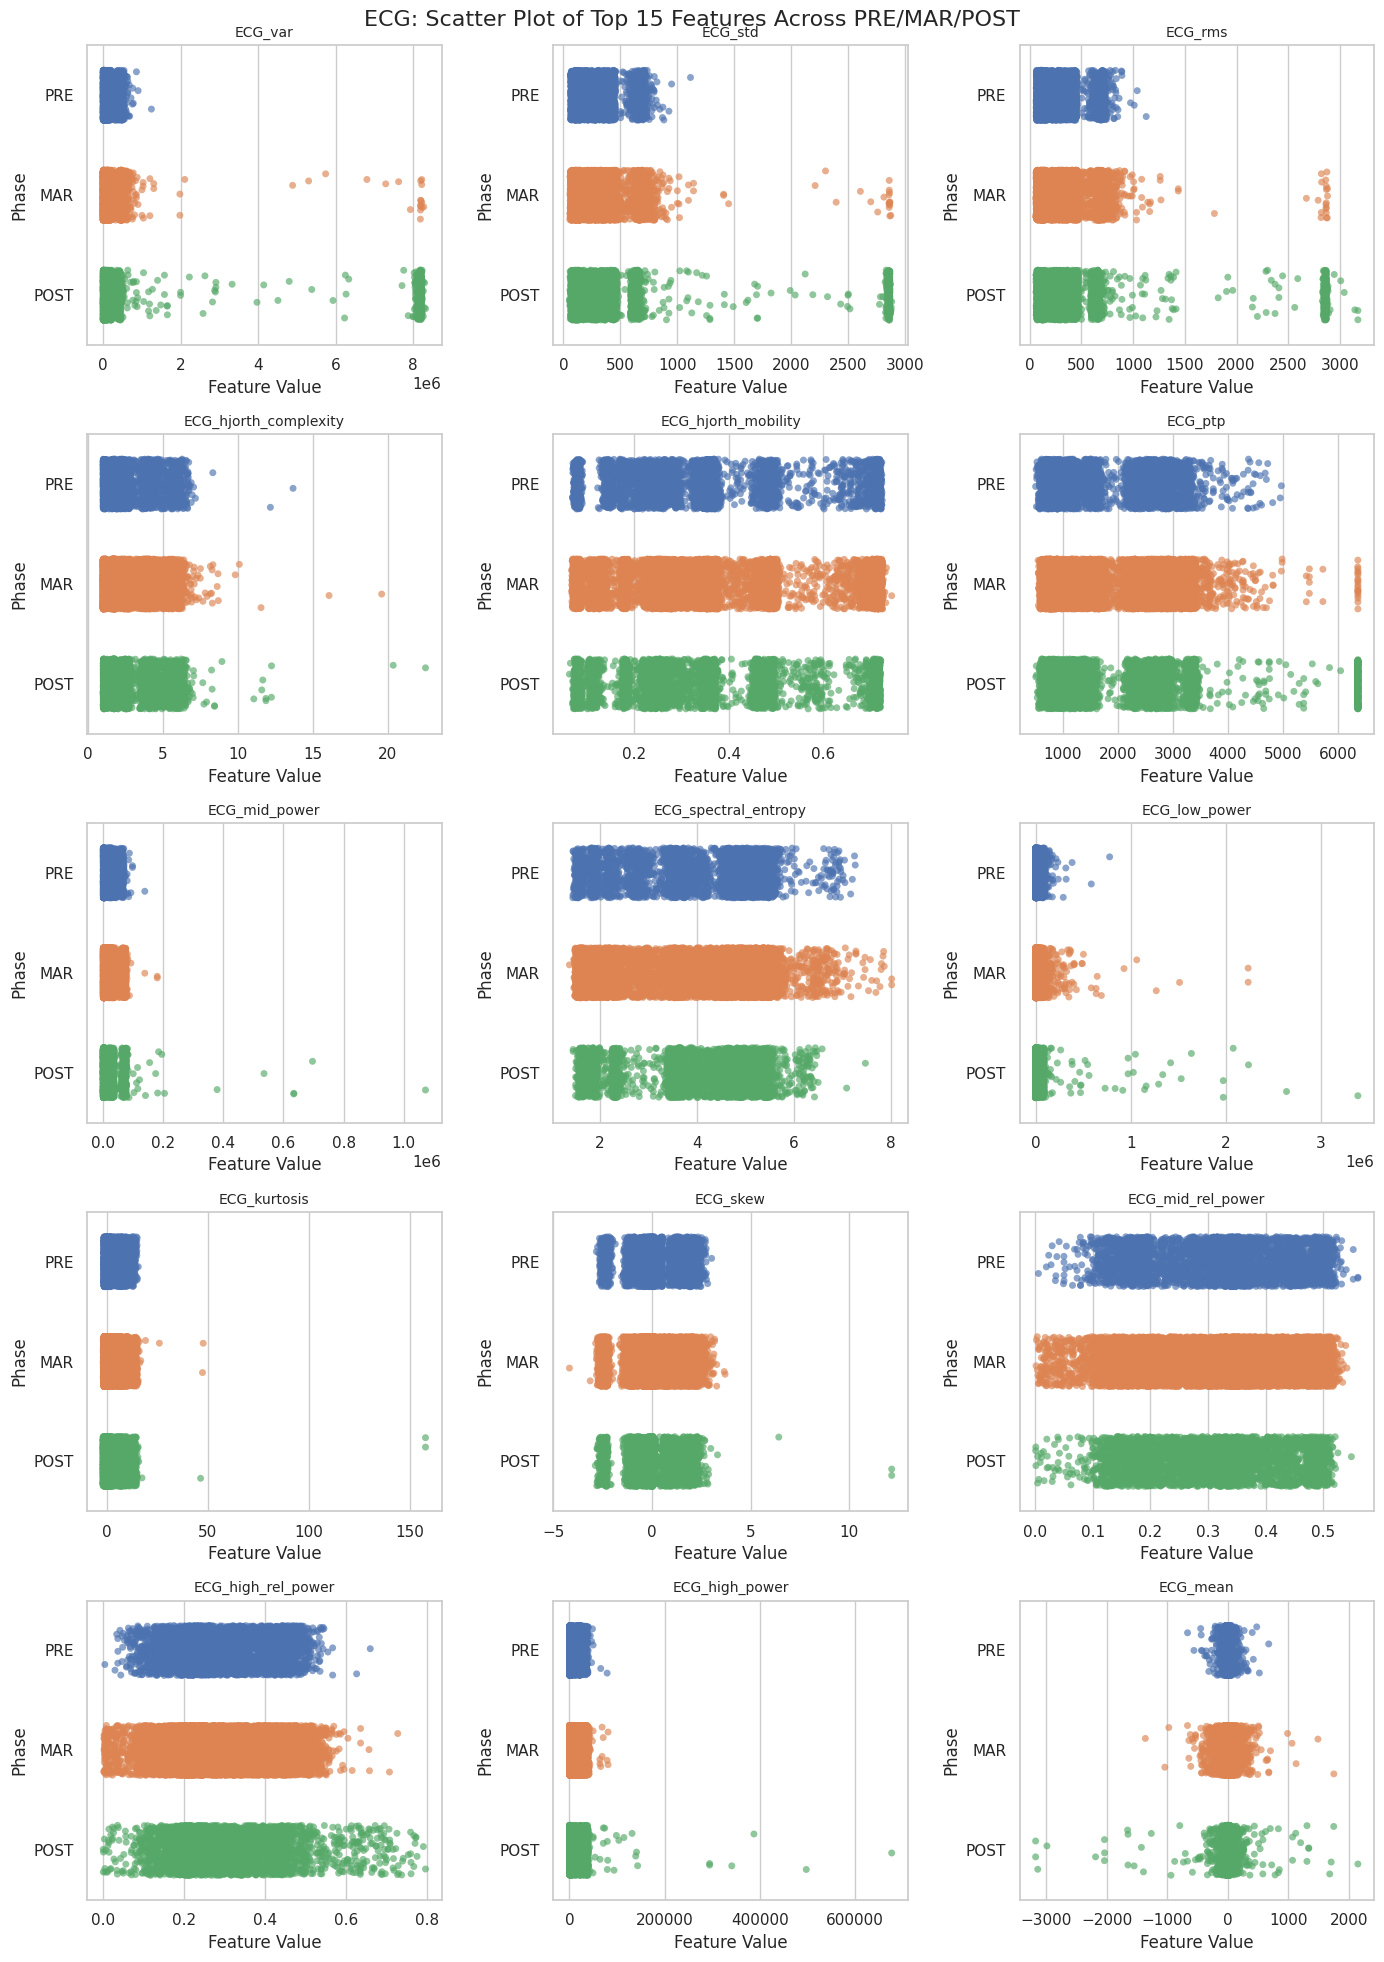

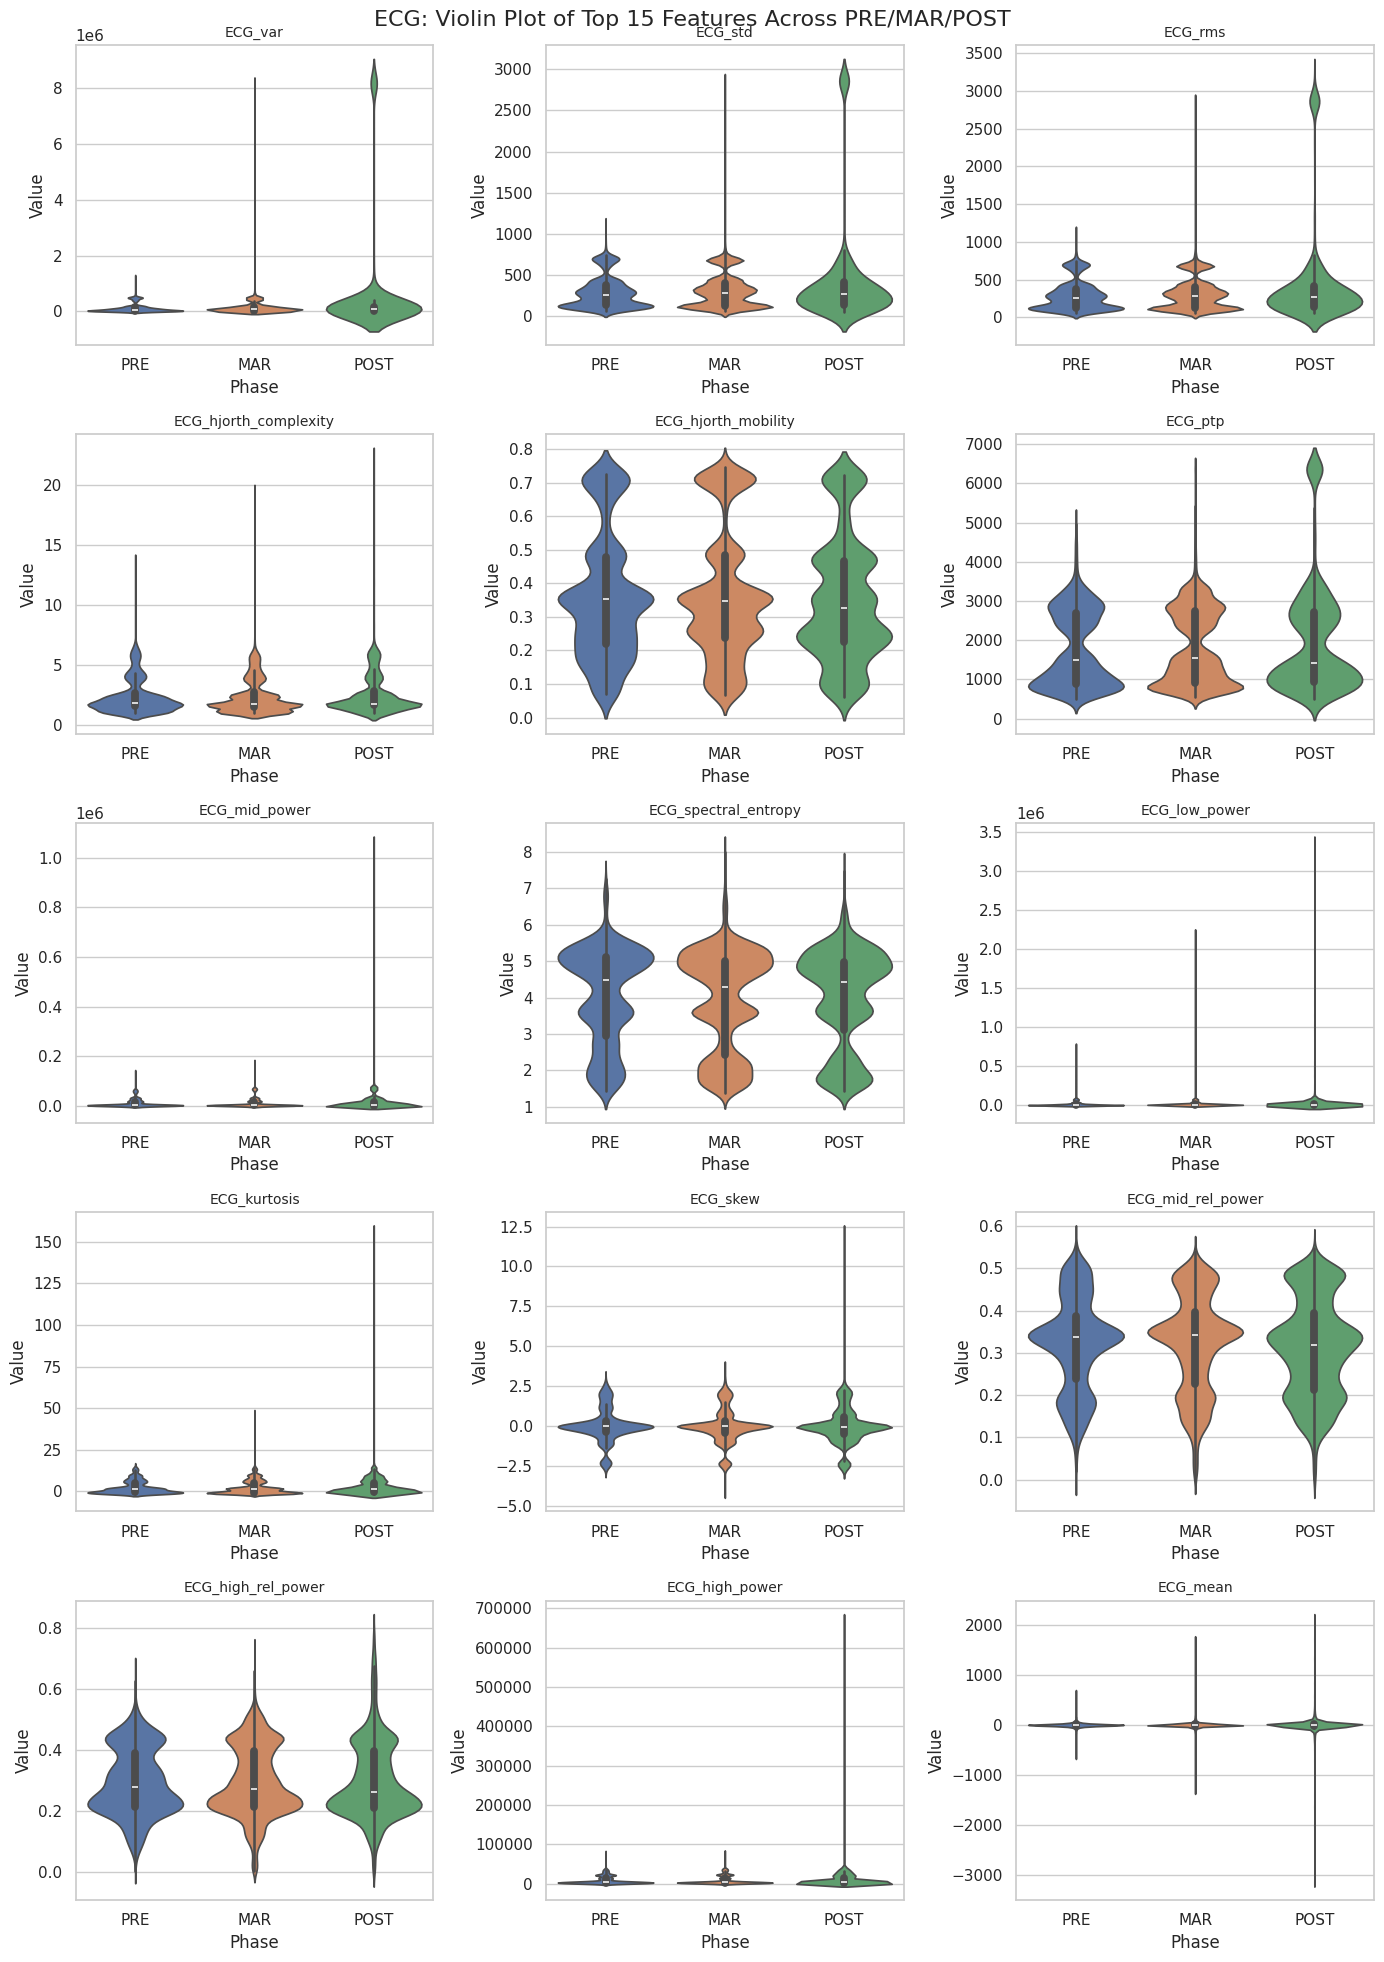

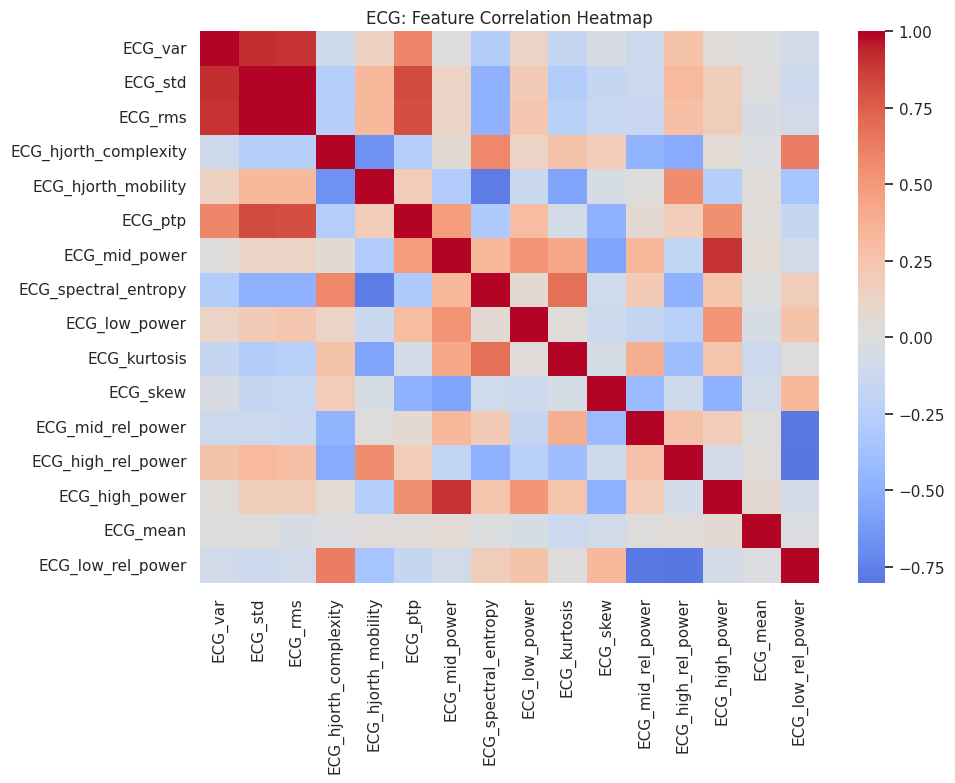

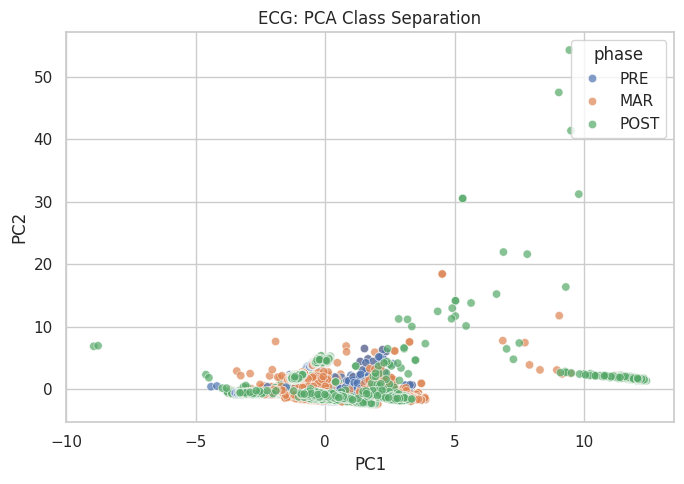

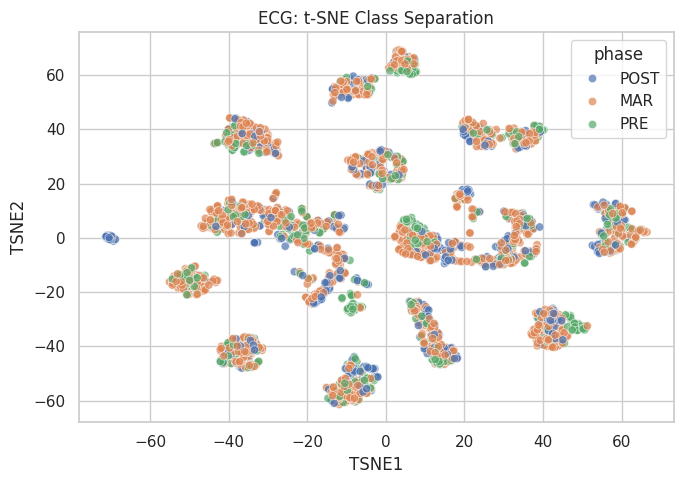


Finished ECG

Processing EEG
EEG shape: (21470, 170)
Columns: ['file_name', 'phase', 'window_id', 'sample_rate', 'split_mode', 'usable_duration_sec', 'window_start_in_phase', 'window_end_in_phase', 'window_start_global', 'window_end_global'] ...
Feature matrix shape for EEG: (21470, 160)
Class distribution:
phase
MAR     12891
POST     4296
PRE      4283
Name: count, dtype: int64

Top 15 ranked features for EEG:
                 feature    anova_F       anova_p  mutual_info  rf_importance  \
0   T3_hjorth_complexity  55.700117  7.452402e-25     0.095506       0.023972   
1     T3_hjorth_mobility  42.128378  5.491483e-19     0.077236       0.012364   
2                 T3_var   5.496584  4.106530e-03     0.219002       0.019287   
3     T4_hjorth_mobility  34.120727  1.603467e-15     0.086833       0.009484   
4     O2_hjorth_mobility  37.733645  4.377477e-17     0.076970       0.009375   
5                 C3_var   5.395754  4.541954e-03     0.205104       0.016743   
6               

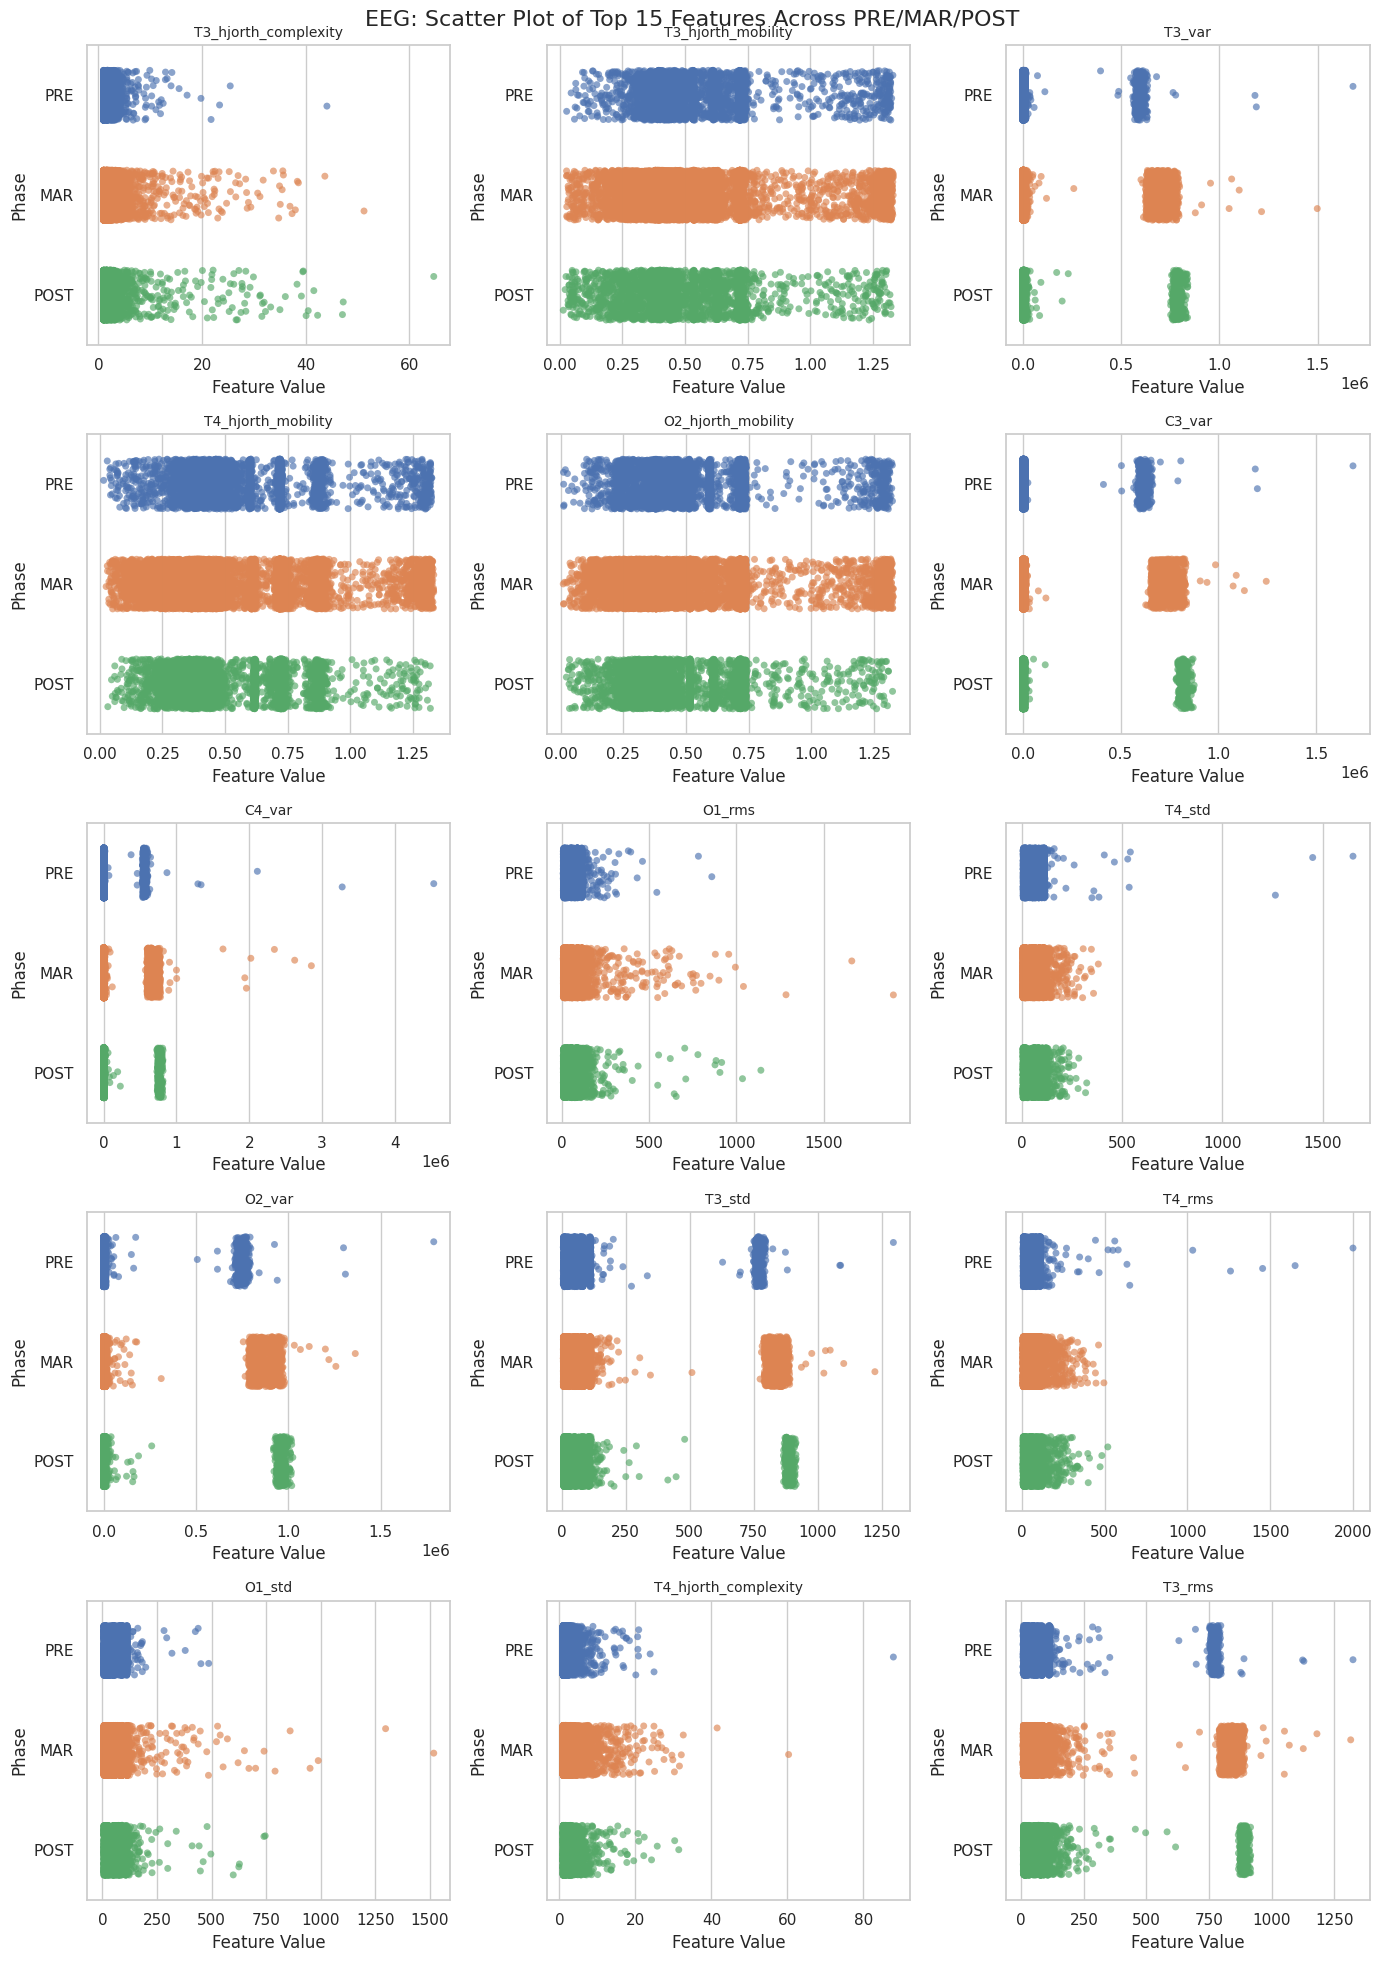

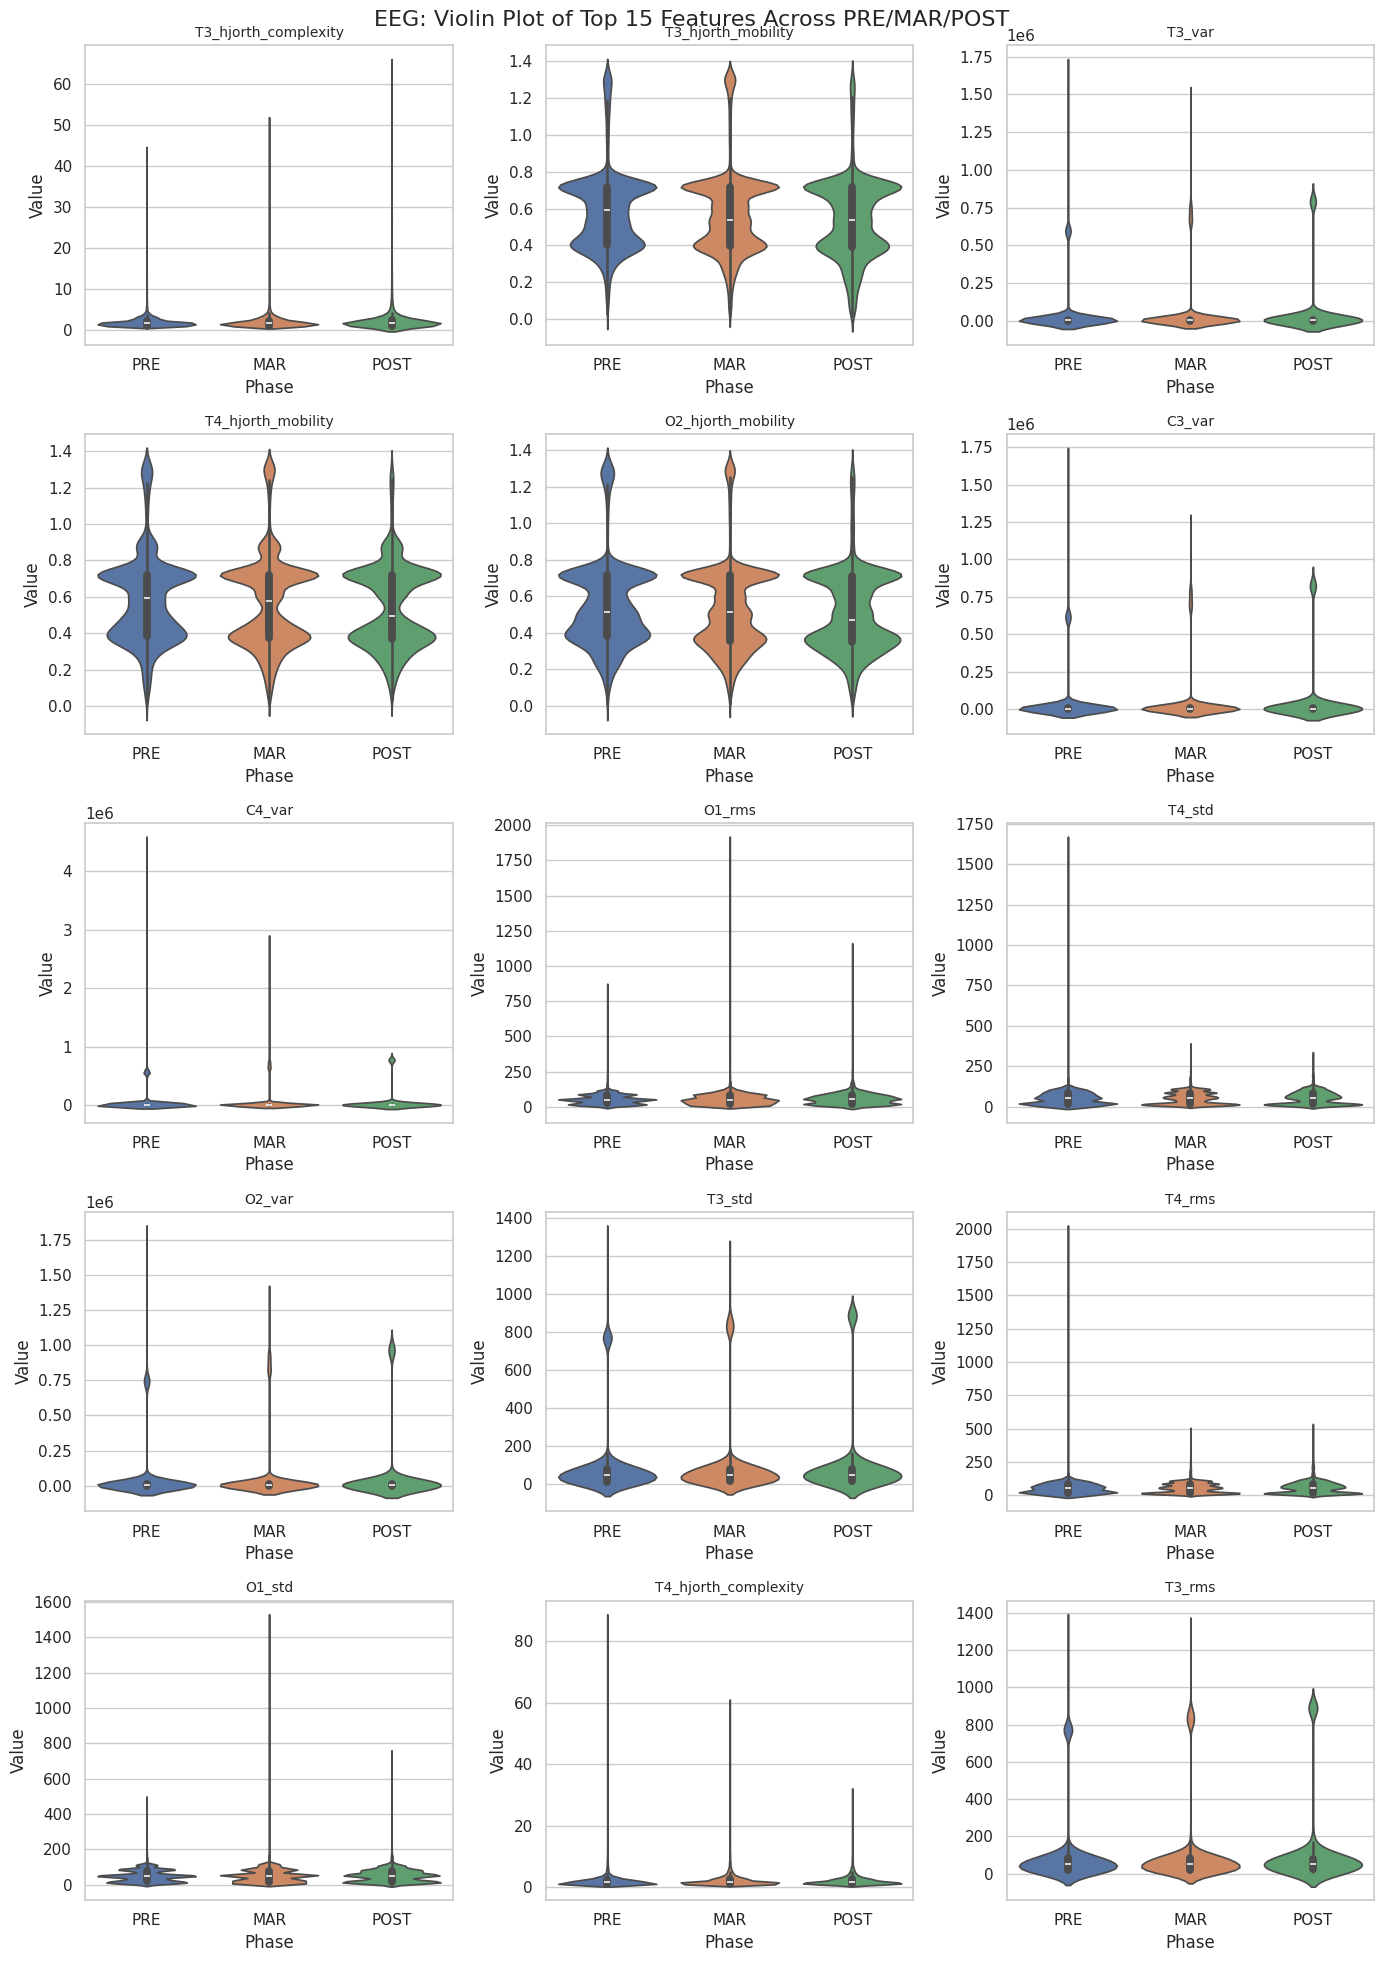

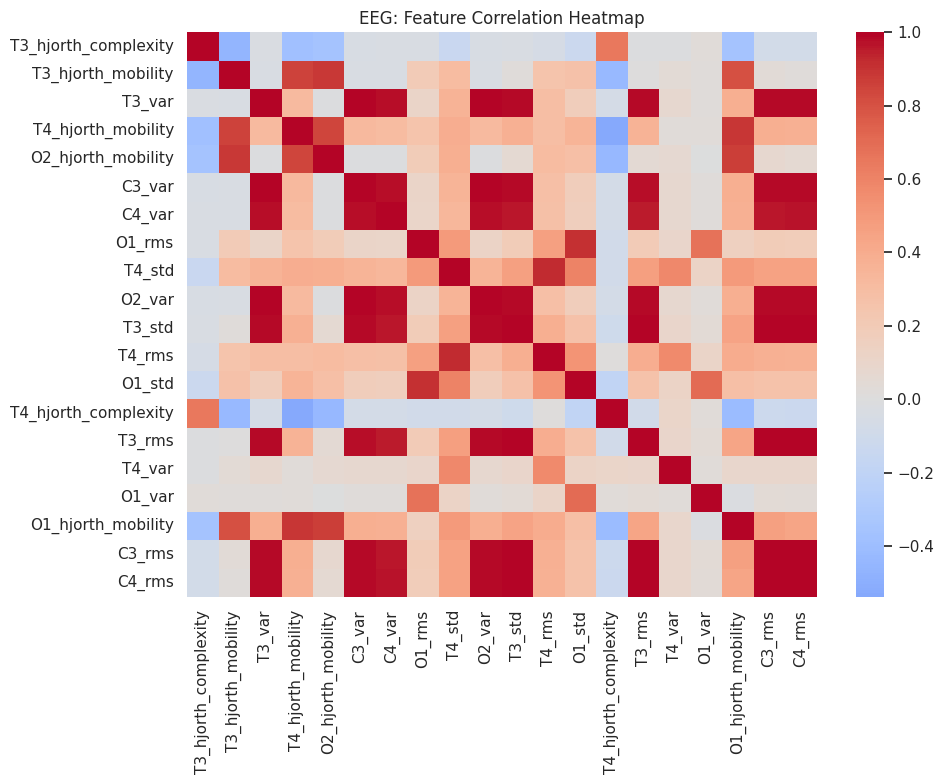

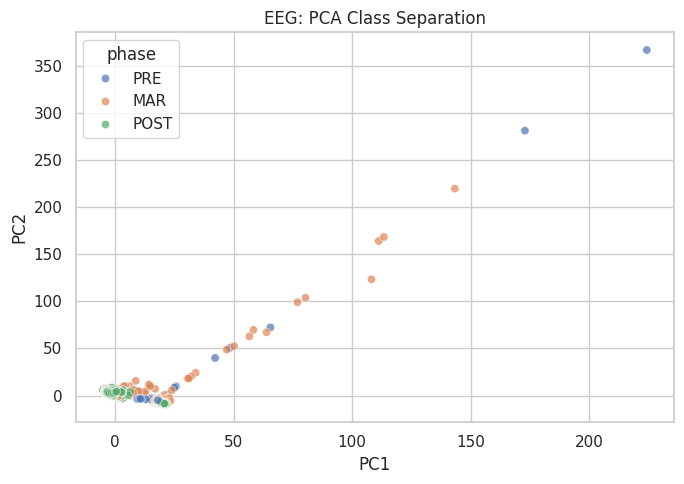

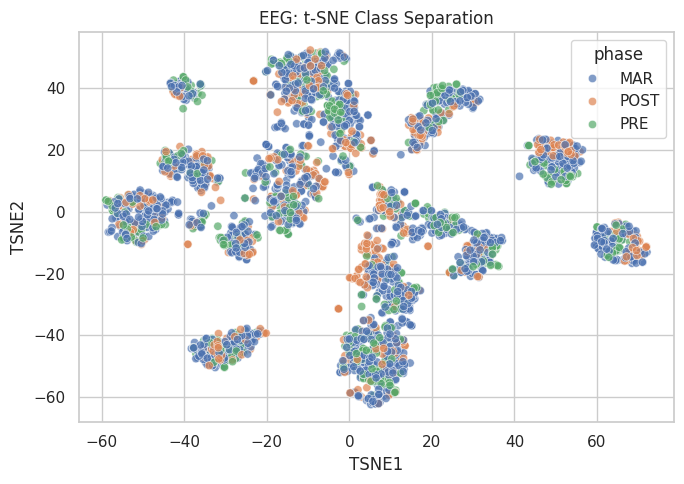


Finished EEG

Processing EMG
EMG shape: (18681, 23)
Columns: ['file_name', 'phase', 'window_id', 'sample_rate', 'EMG_mean', 'EMG_std', 'EMG_var', 'EMG_skew', 'EMG_kurtosis', 'EMG_rms'] ...
Feature matrix shape for EMG: (18681, 19)
Class distribution:
phase
MAR     11217
POST     3737
PRE      3727
Name: count, dtype: int64

Top 15 ranked features for EMG:
                  feature     anova_F       anova_p  mutual_info  \
0     EMG_waveform_length  164.282631  1.875990e-71     0.098849   
1           EMG_mid_power  115.885610  9.576728e-51     0.096584   
2          EMG_high_power   42.997114  2.341238e-19     0.087875   
3           EMG_low_power   11.207277  1.366657e-05     0.075277   
4       EMG_mid_rel_power   32.905496  5.425529e-15     0.062539   
5       EMG_low_rel_power   29.302876  1.967190e-13     0.052845   
6                 EMG_ptp  166.346907  2.467858e-72     0.037294   
7      EMG_high_rel_power    6.834171  1.079053e-03     0.070217   
8     EMG_hjorth_mobility   1

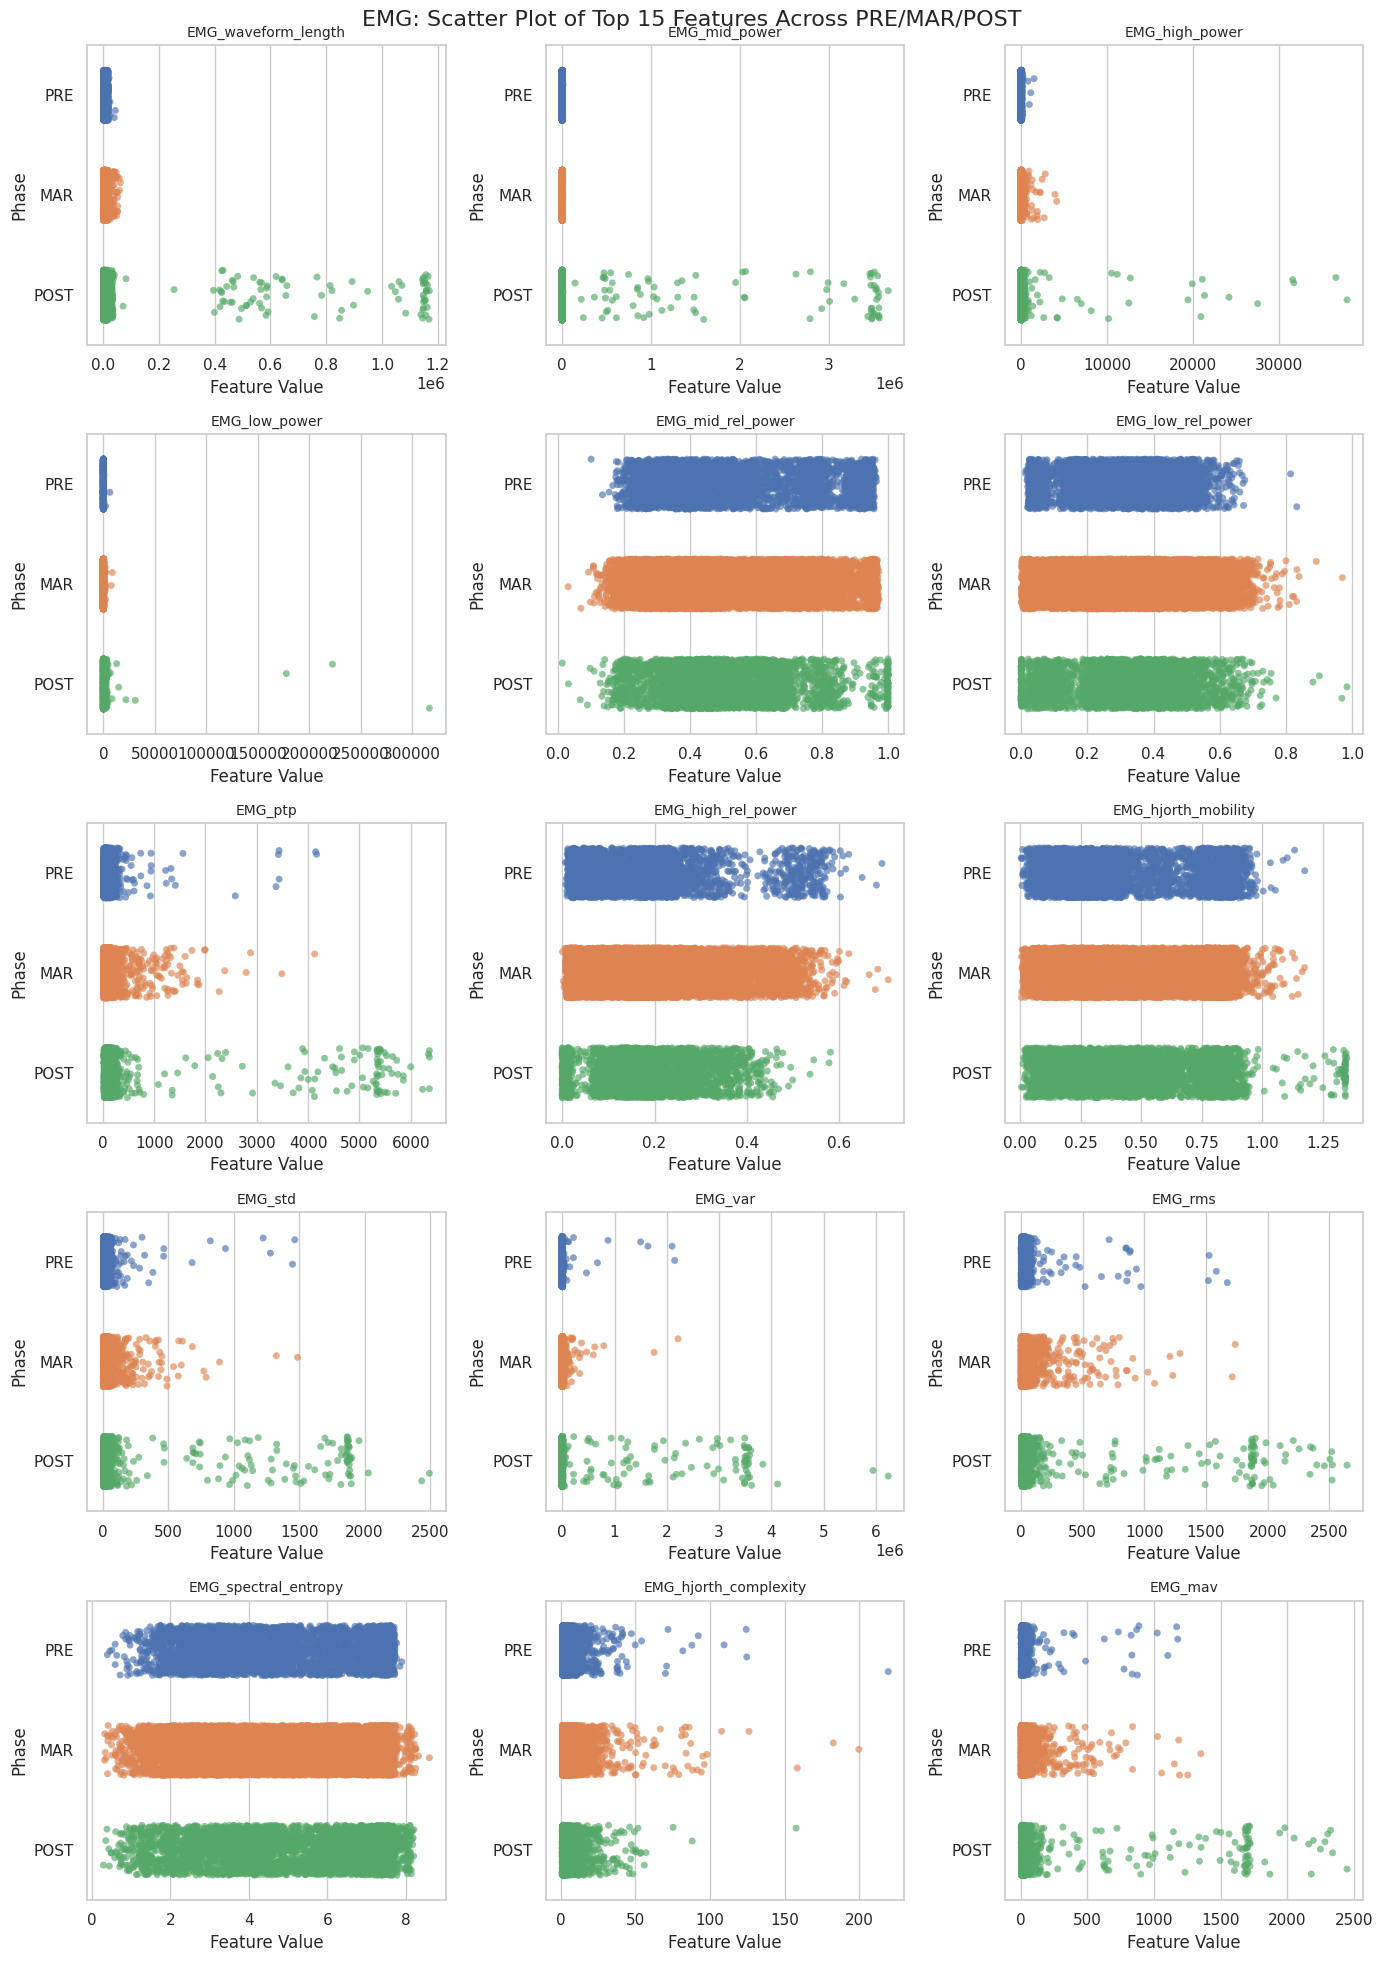

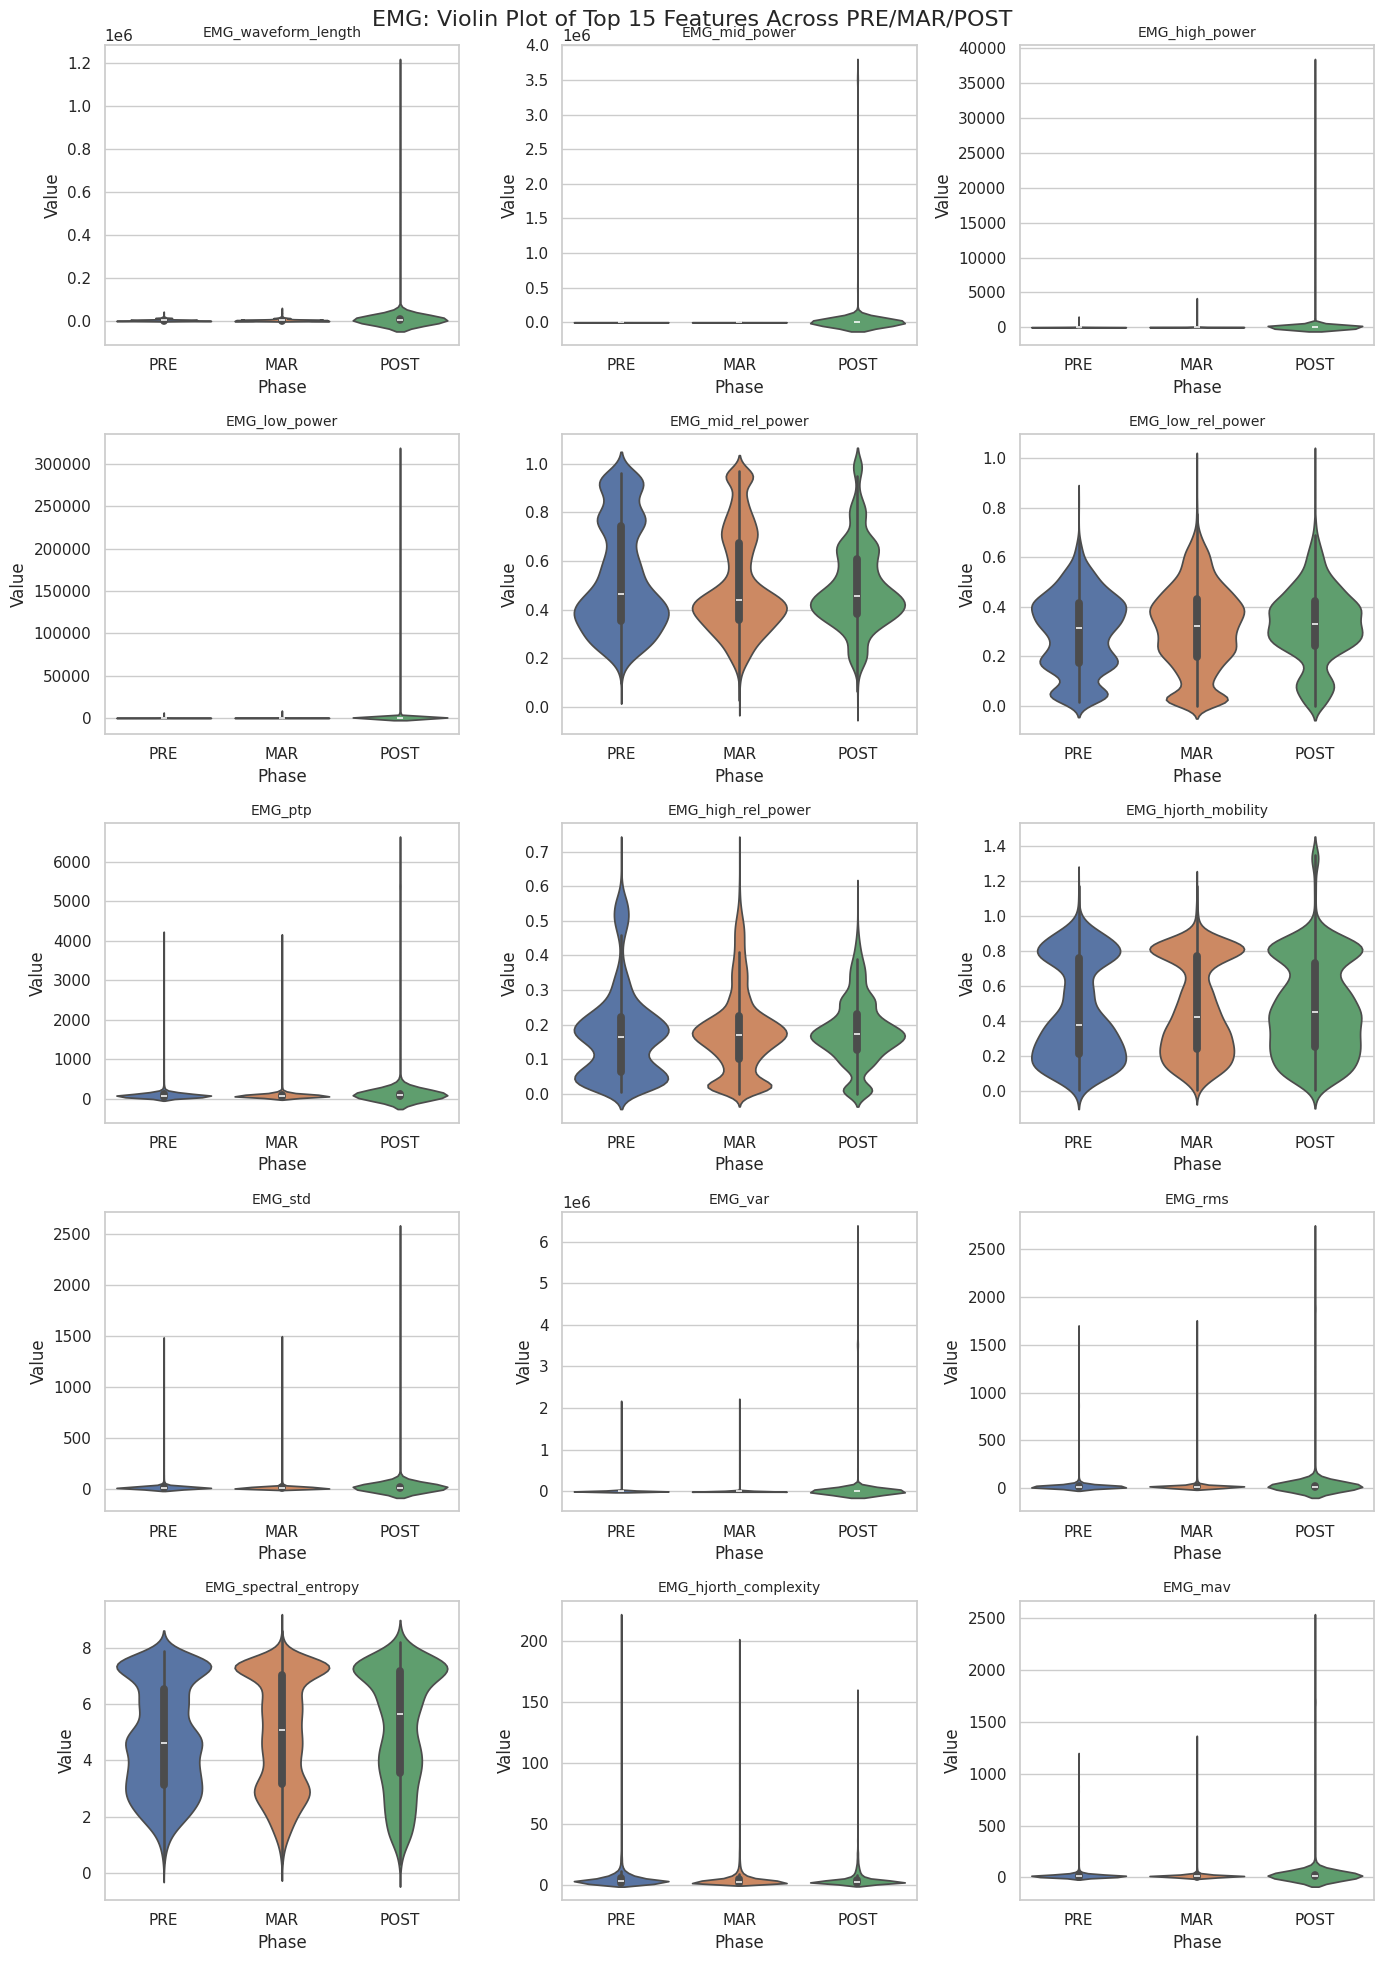

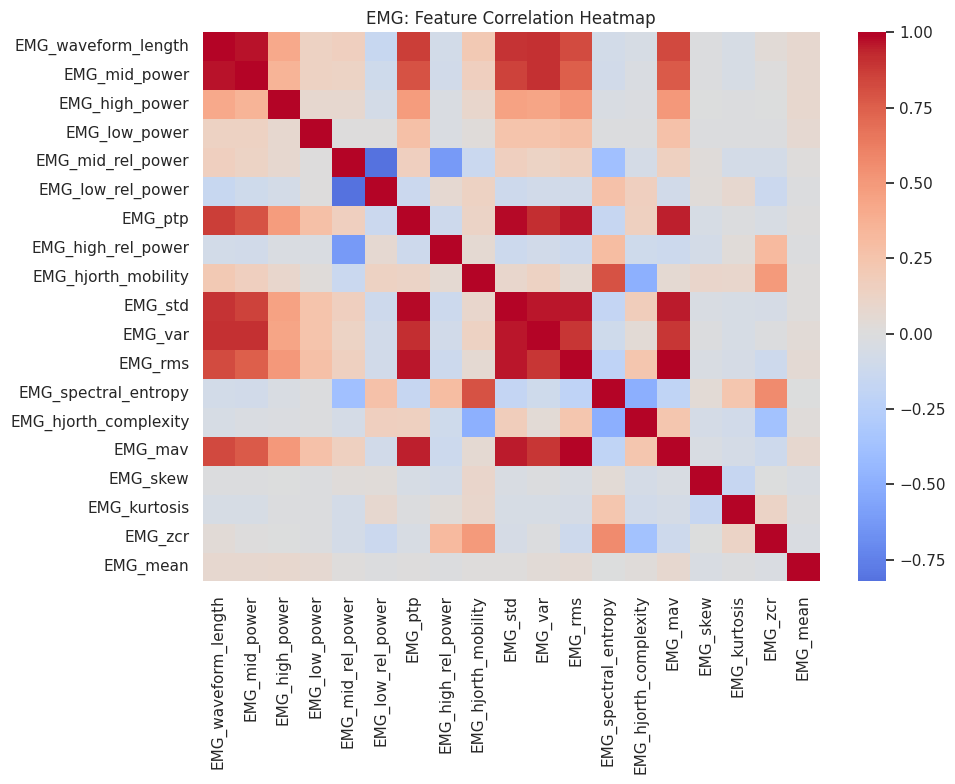

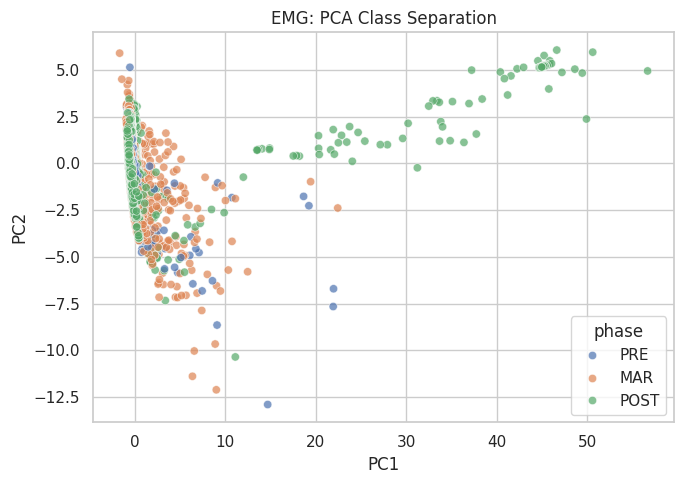

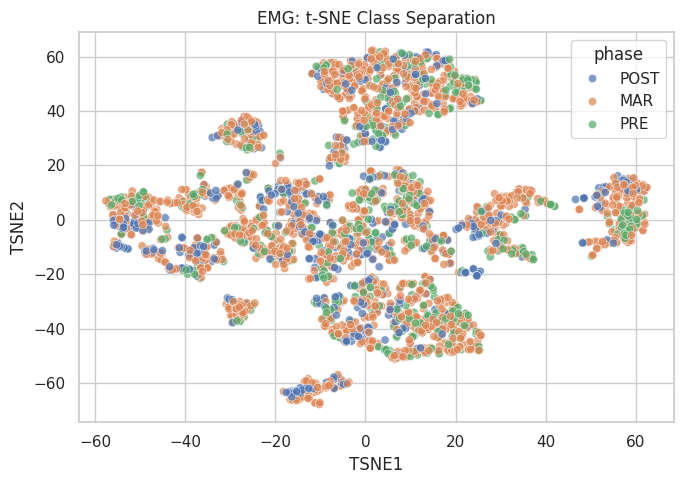


Finished EMG

Processing Fusion
Fusion shape: (18681, 198)
Columns: ['file_name', 'phase', 'window_id', 'FP1_mean', 'FP1_std', 'FP1_var', 'FP1_skew', 'FP1_kurtosis', 'FP1_rms', 'FP1_ptp'] ...
Feature matrix shape for Fusion: (18681, 195)
Class distribution:
phase
MAR     11217
POST     3737
PRE      3727
Name: count, dtype: int64

Top 15 ranked features for Fusion:
                  feature     anova_F        anova_p  mutual_info  \
0                 ECG_std  239.984039  1.238414e-103     0.129186   
1                 ECG_var  419.545635  5.858431e-179     0.128979   
2                 ECG_rms  264.715697  4.311517e-114     0.120363   
3     EMG_waveform_length  164.282631   1.875990e-71     0.099829   
4           EMG_mid_power  115.885610   9.576728e-51     0.095975   
5    T3_hjorth_complexity   56.552339   3.263585e-25     0.087816   
6          EMG_high_power   42.997114   2.341238e-19     0.087823   
7                 ECG_ptp   72.486564   4.375503e-32     0.085762   
8       EM

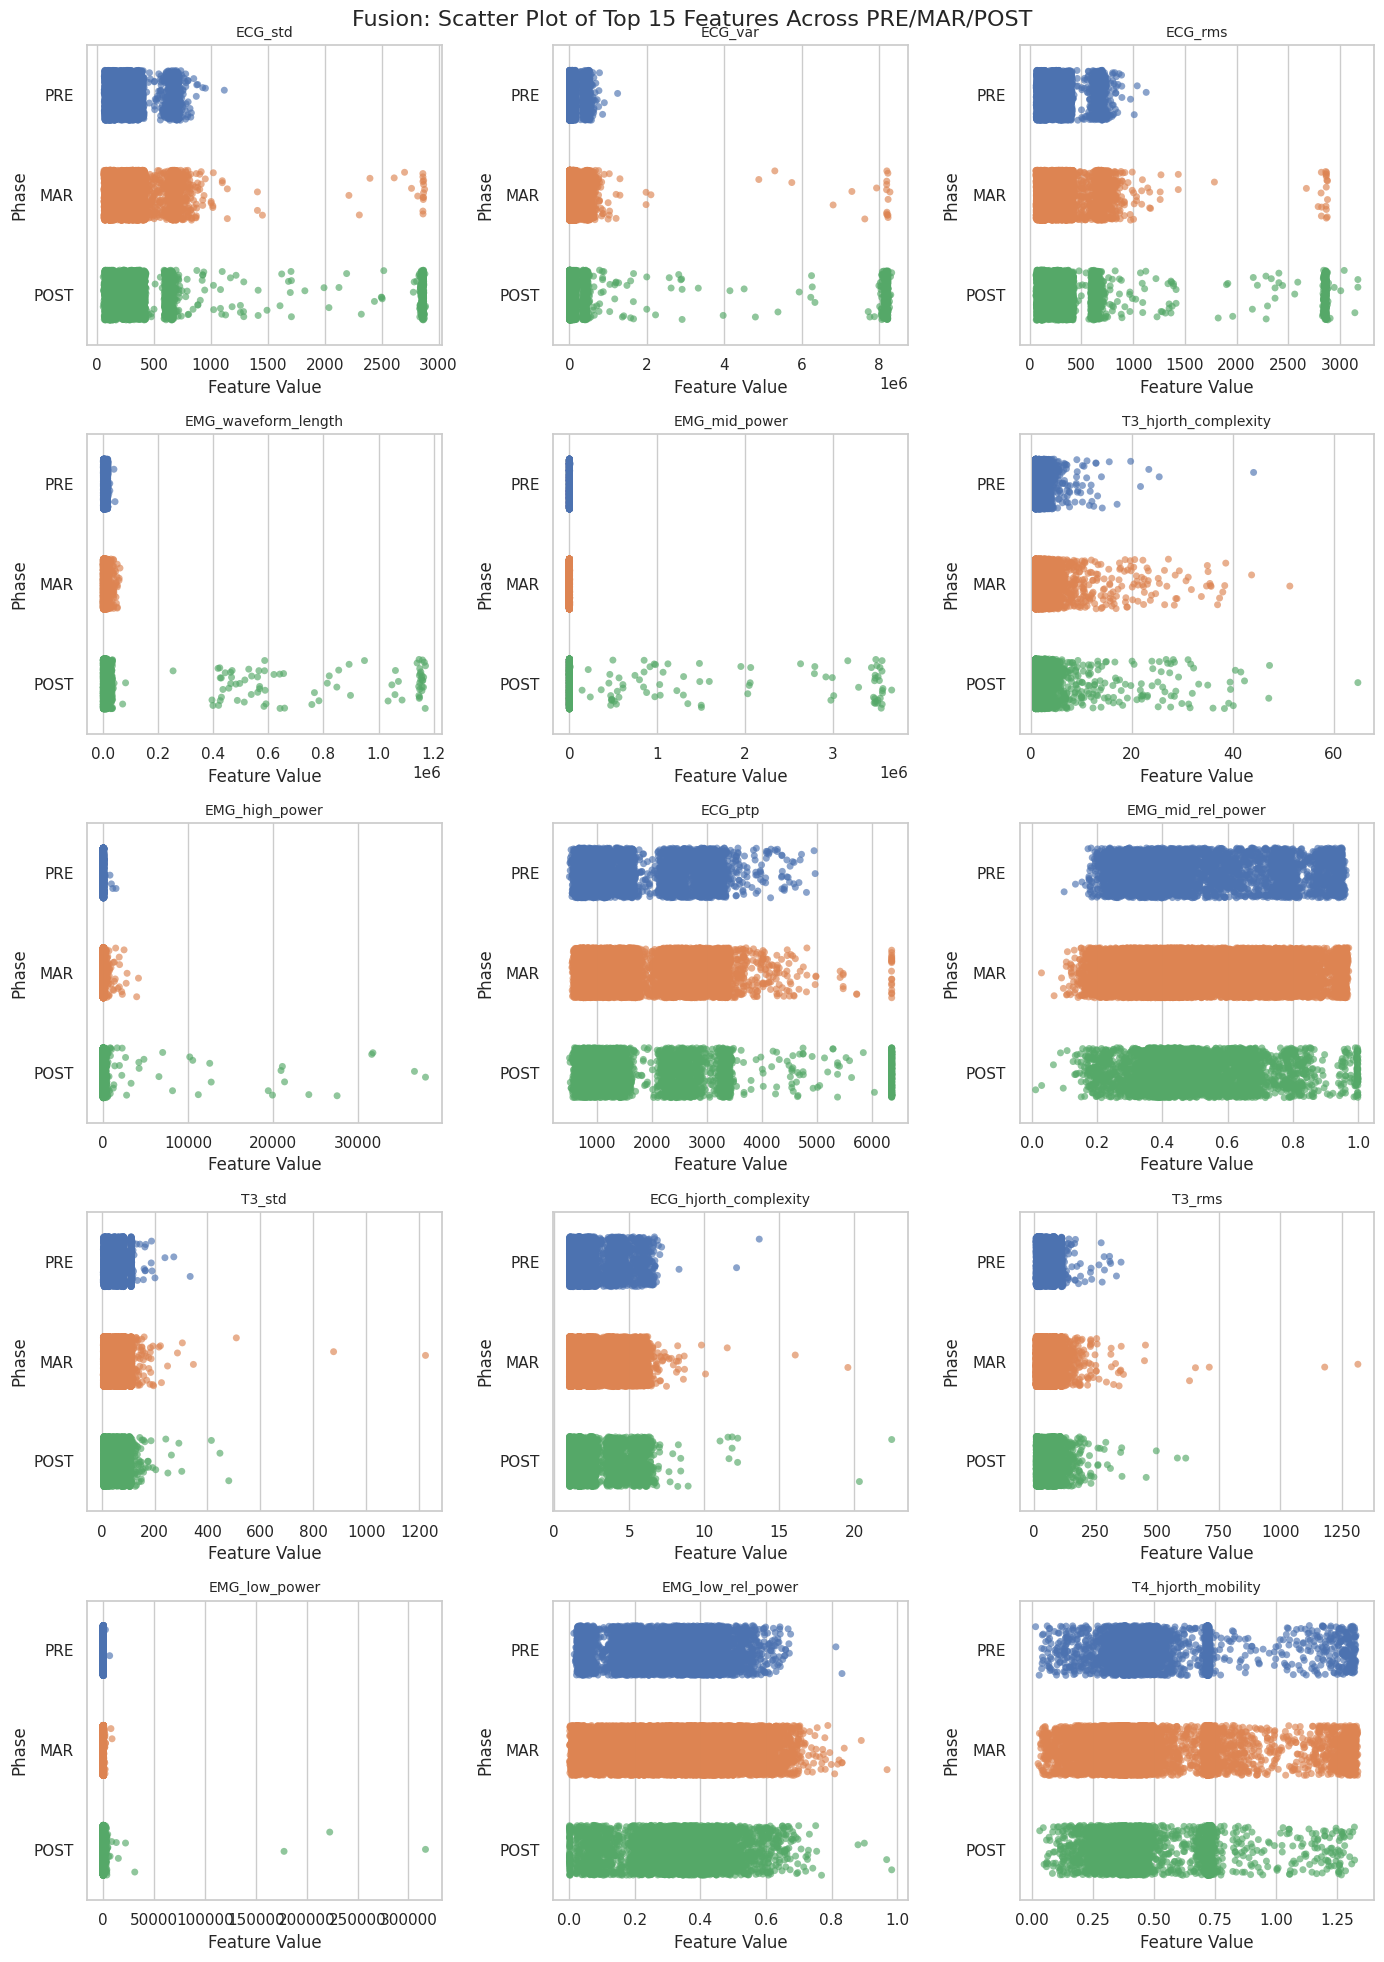

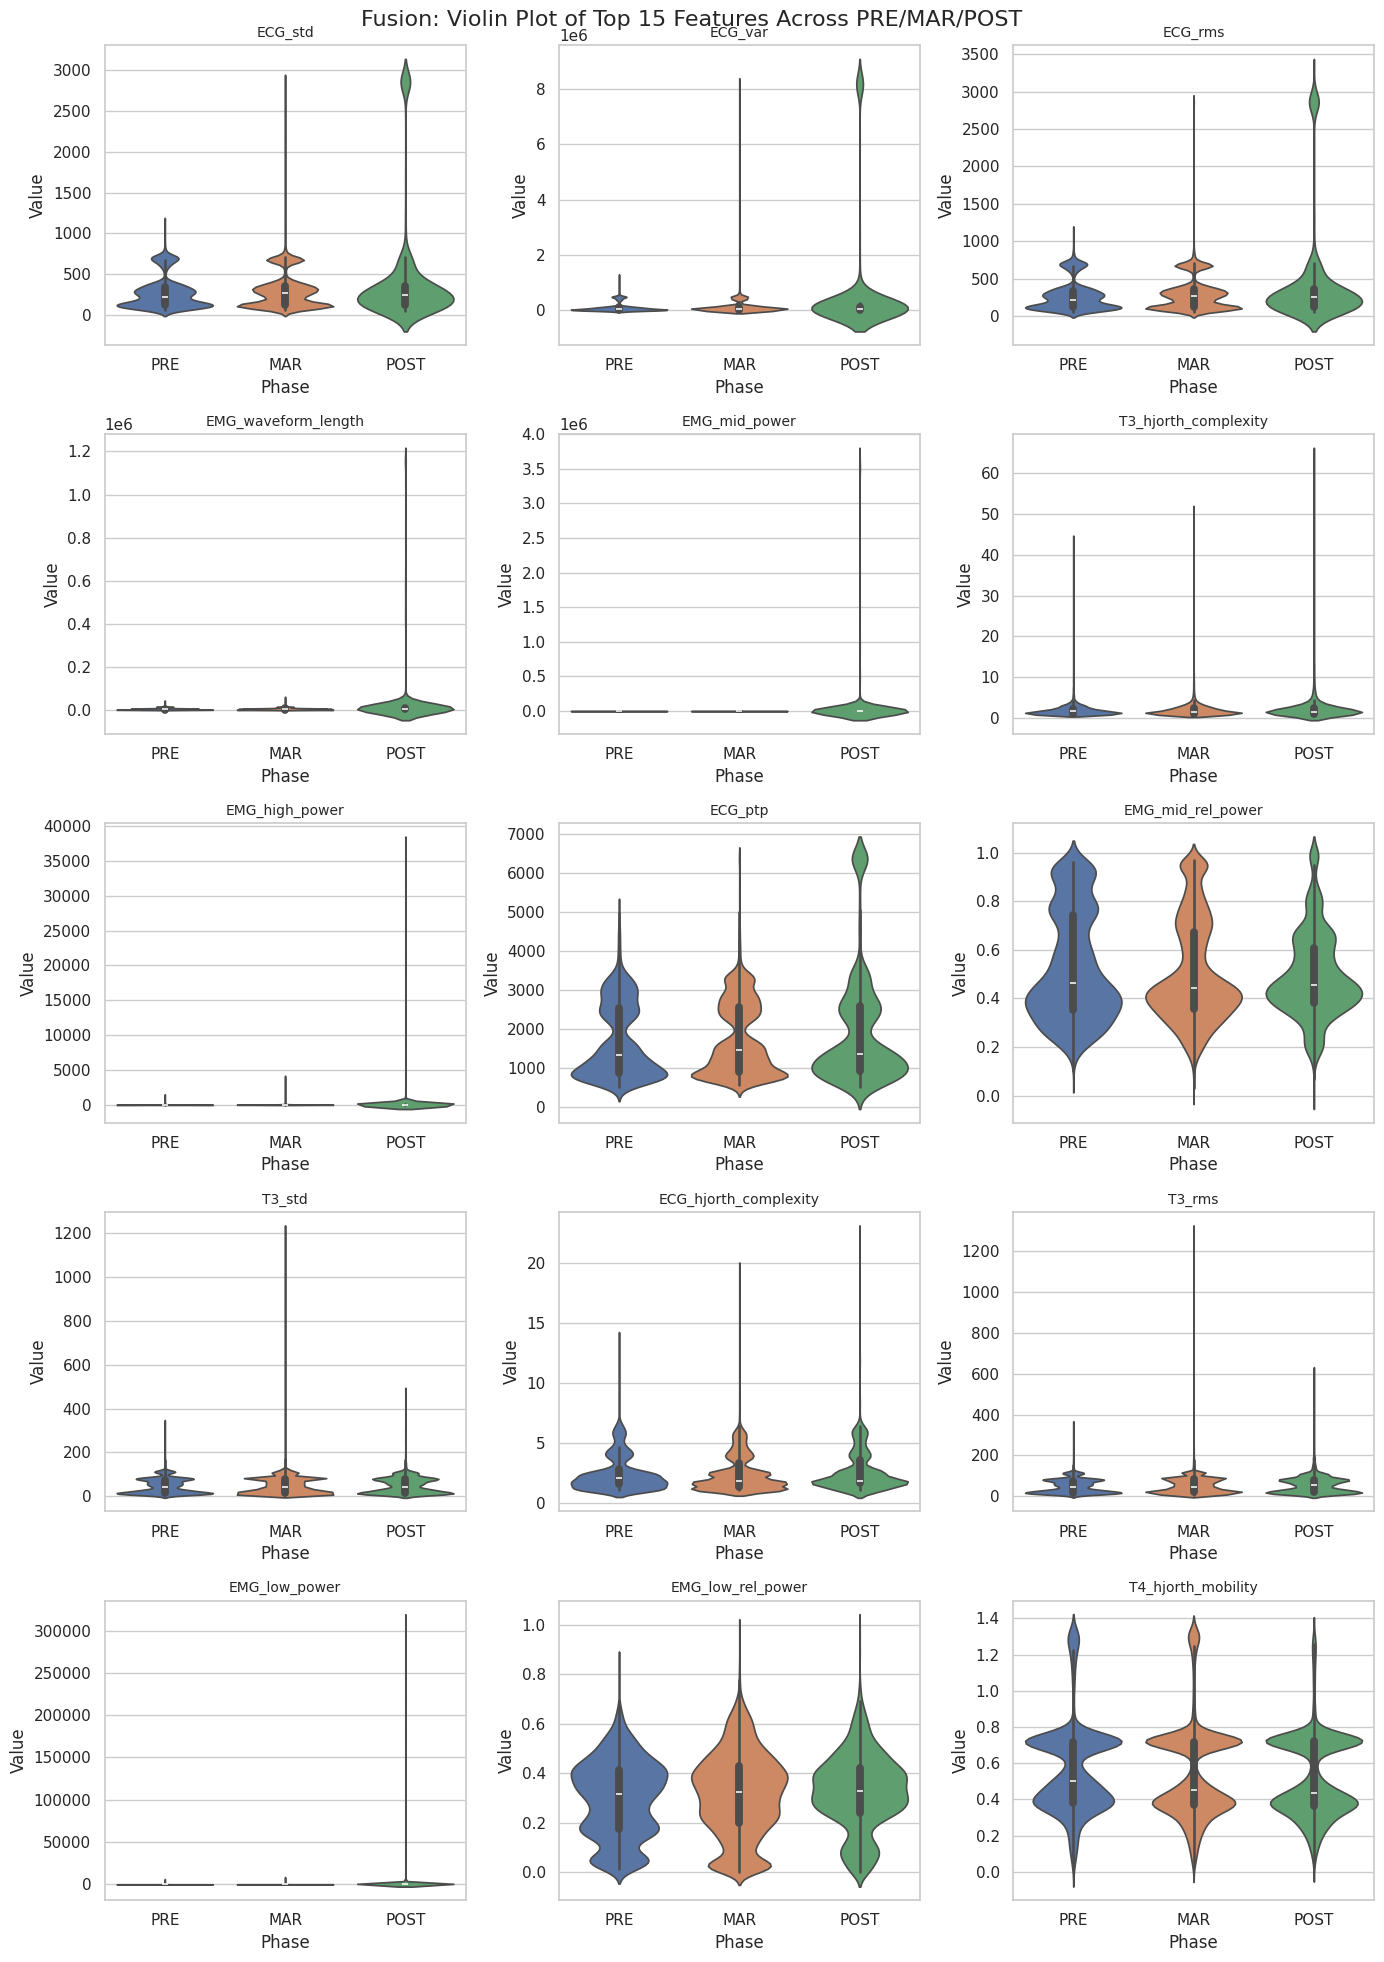

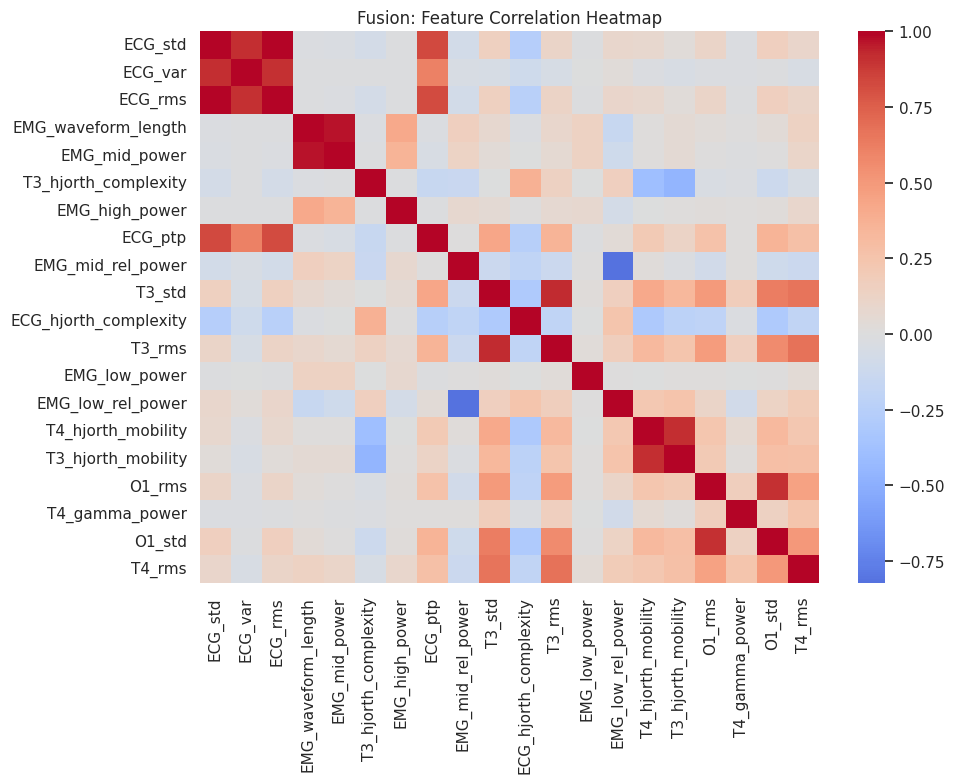

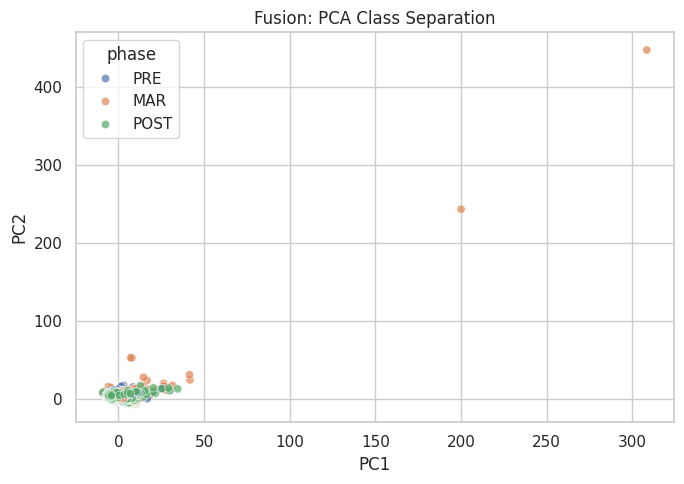

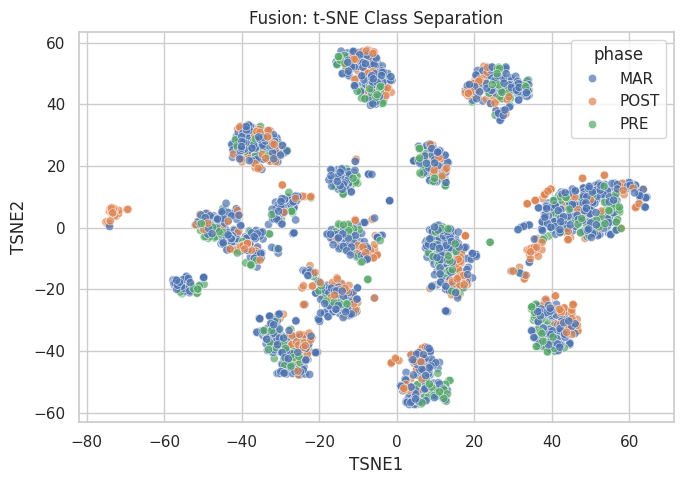


Finished Fusion



In [ ]:
for modality, path in files.items():
    print("="*80)
    print(f"Processing {modality}")
    print("="*80)

    # Load CSV
    df = pd.read_csv(path)
    print(f"{modality} shape: {df.shape}")
    print("Columns:", df.columns[:10].tolist(), "...")


    save_dir = os.path.join(output_root, modality)
    os.makedirs(save_dir, exist_ok=True)


    X = prepare_feature_matrix(df)
    y = df["phase"]

    print(f"Feature matrix shape for {modality}: {X.shape}")
    print("Class distribution:")
    print(y.value_counts())


    rank_df = compute_feature_ranking(X, y)
    rank_df.to_csv(os.path.join(save_dir, f"{modality}_feature_ranking.csv"), index=False)

    print(f"\nTop 15 ranked features for {modality}:")
    print(rank_df.head(15))

    top_features = rank_df["feature"].tolist()


    plot_top15_scatter(df, top_features, modality, save_dir)
    plot_top15_violinplots(df, top_features, modality, save_dir)
    plot_correlation_heatmap(df, top_features, modality, save_dir)
    plot_pca(X, y, modality, save_dir)
    plot_tsne(X, y, modality, save_dir)

    print(f"\nFinished {modality}\n")


Processing: ECG

Running Logistic Regression

Running SVM

Running Random Forest

Running XGBoost

Running kNN

Processing: EEG

Running Logistic Regression

Running SVM

Running Random Forest

Running XGBoost

Running kNN

Processing: EMG

Running Logistic Regression

Running SVM

Running Random Forest

Running XGBoost

Running kNN

Processing: Fusion

Running Logistic Regression

Running SVM

Running Random Forest

Running XGBoost

Running kNN


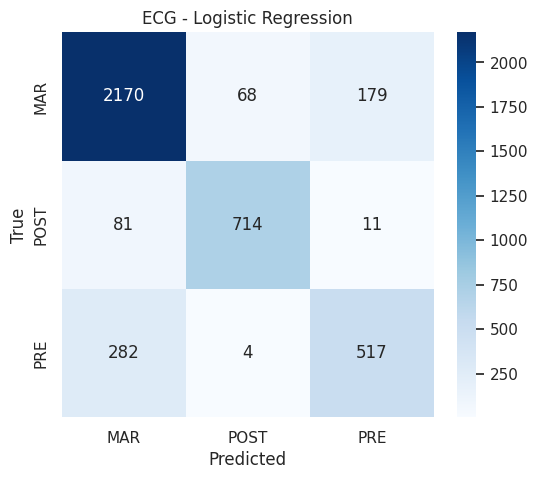

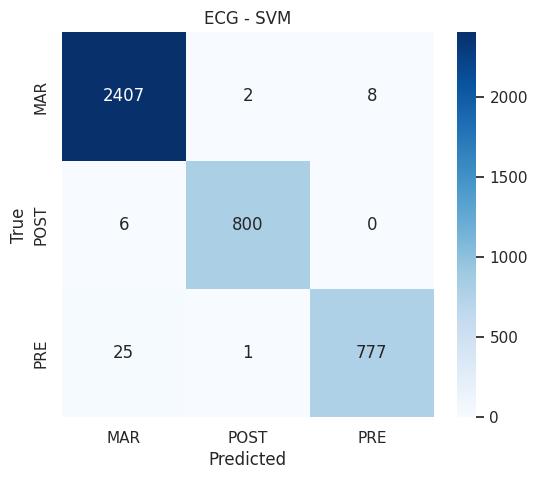

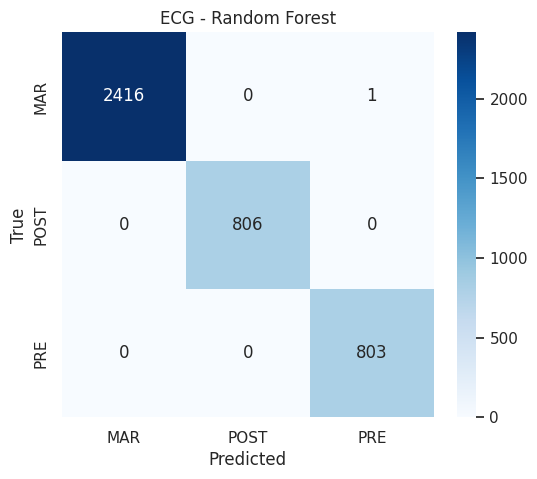

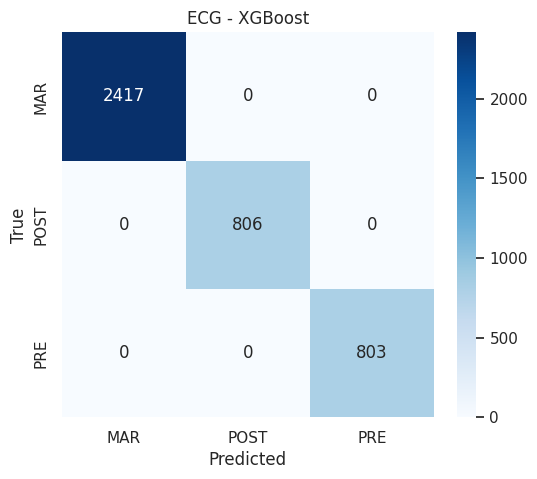

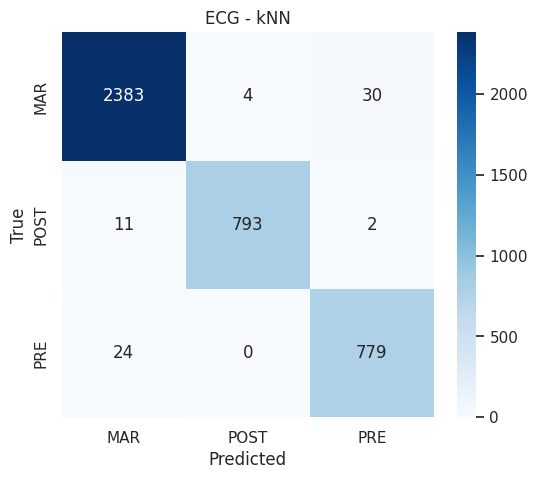

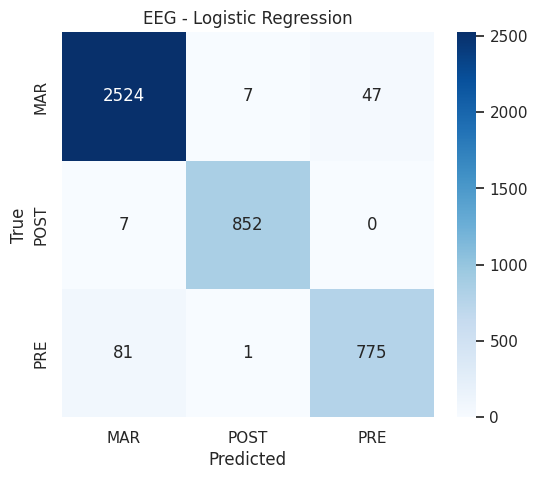

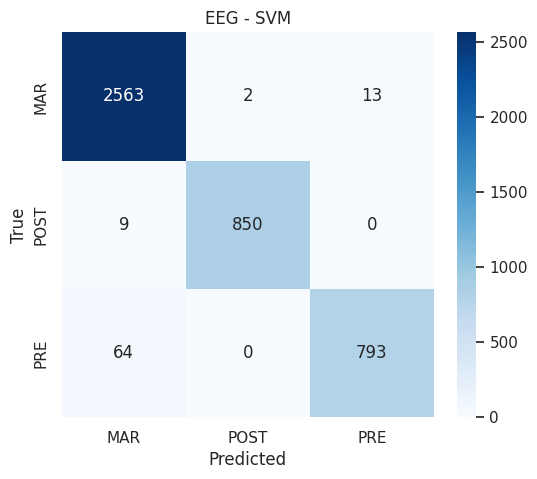

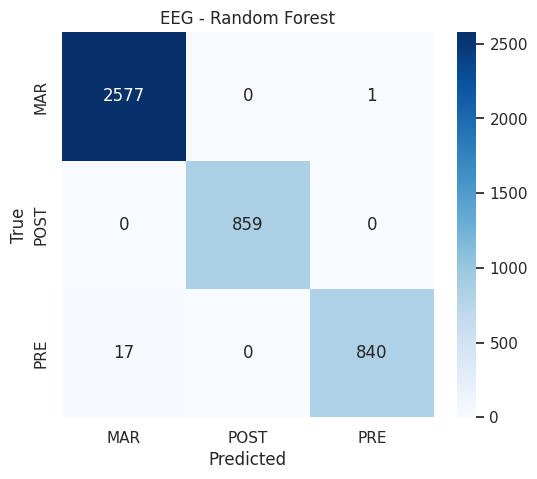

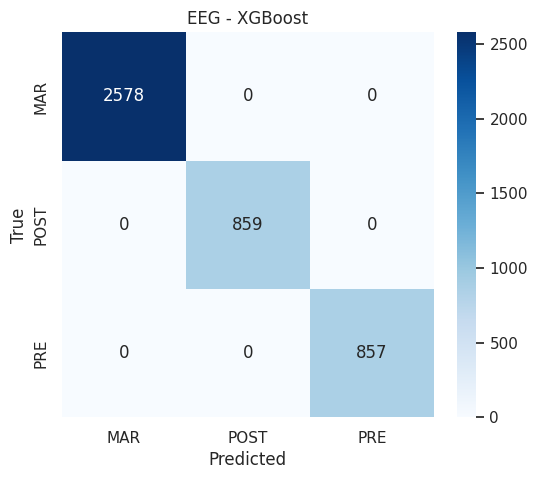

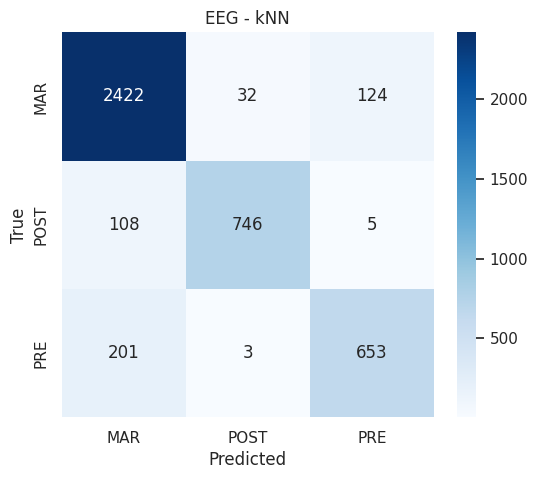

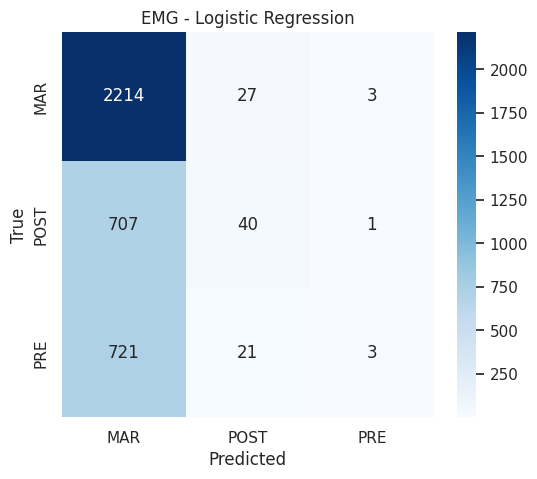

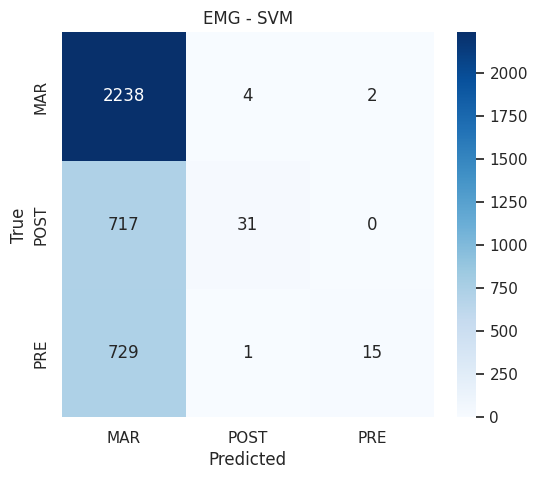

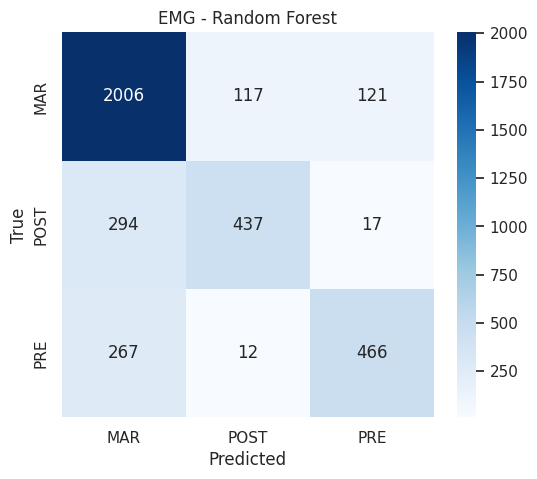

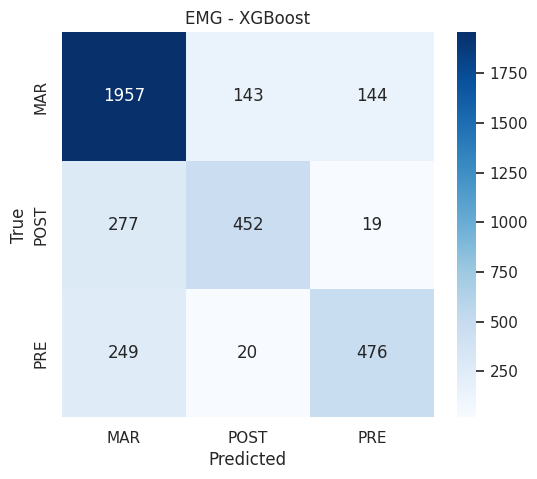

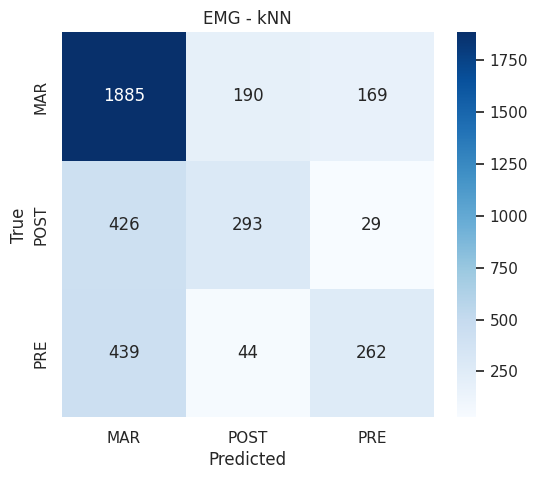

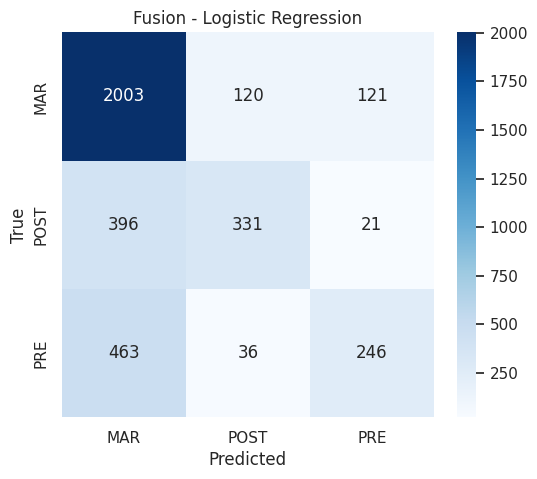

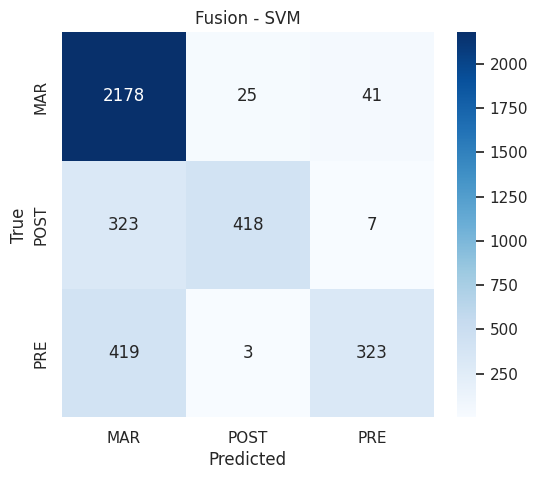

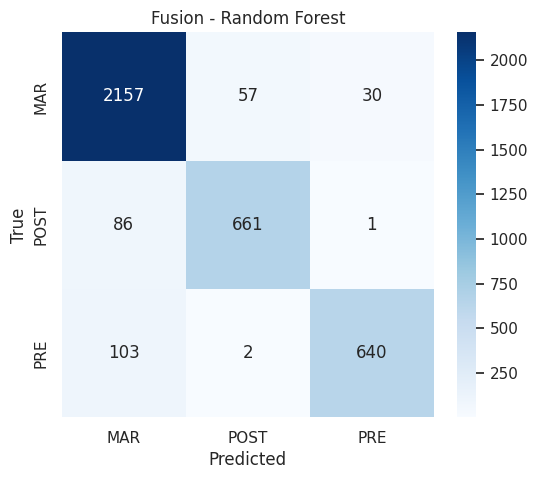

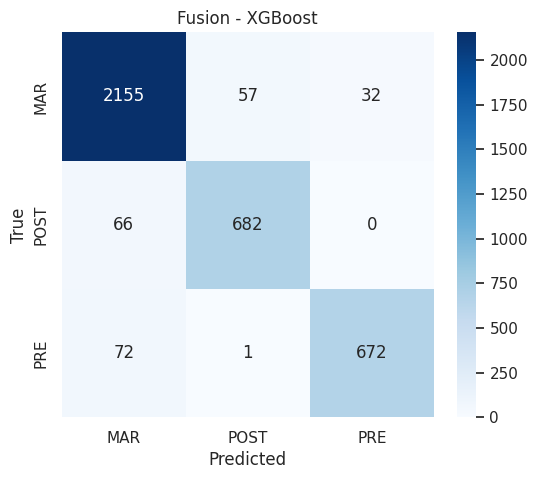

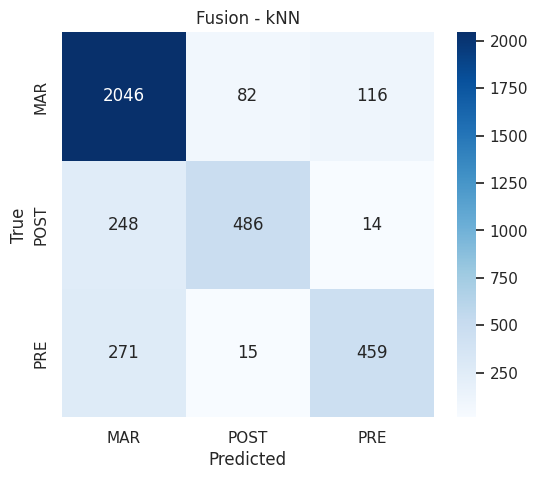

   Modality                Model  Accuracy  Precision    Recall        F1  \
18   Fusion              XGBoost  0.938988   0.938661  0.924706  0.931390   
17   Fusion        Random Forest  0.925341   0.930431  0.901327  0.914790   
19   Fusion                  kNN  0.800375   0.803522  0.725868  0.756446   
16   Fusion                  SVM  0.781108   0.851243  0.654323  0.707518   
15   Fusion  Logistic Regression  0.690393   0.671184  0.555106  0.584948   
12      EMG        Random Forest  0.778432   0.775022  0.701222  0.729983   
13      EMG              XGBoost  0.772010   0.756011  0.705103  0.726371   
14      EMG                  kNN  0.652930   0.603666  0.527802  0.549790   
11      EMG                  SVM  0.611185   0.783652  0.352968  0.291171   
10      EMG  Logistic Regression  0.603960   0.497008  0.348045  0.285322   
8       EEG              XGBoost  1.000000   1.000000  1.000000  1.000000   
7       EEG        Random Forest  0.995808   0.997419  0.993258  0.995306   

In [ ]:
#Classification

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score,
    confusion_matrix, classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from xgboost import XGBClassifier

import seaborn as sns
import matplotlib.pyplot as plt

#paths
files = {
    "ECG": "/content/drive/MyDrive/Sourcedata/extracted_data/ECG_features.csv",
    "EEG": "/content/drive/MyDrive/Sourcedata/extracted_data/EEG_features.csv",
    "EMG": "/content/drive/MyDrive/Sourcedata/extracted_data/EMG_features.csv",
    "Fusion": "/content/drive/MyDrive/Sourcedata/extracted_data/Fusion_features.csv"
}

#models
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM": SVC(probability=True),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        eval_metric='mlogloss',
        use_label_encoder=False,
        random_state=42
    ),
    "kNN": KNeighborsClassifier(n_neighbors=5)
}
#remove meta-columns
meta_cols = [
    'file_name', 'window_id', 'sample_rate',
    'split_mode', 'subject_id'
]

#loop starts
all_results = []

for modality, path in files.items():

    print("\n" + "="*70)
    print("Processing:", modality)
    print("="*70)

    df = pd.read_csv(path)

    # Target
    y = df['phase']

    # Drop metadata
    X = df.drop(columns=[c for c in meta_cols if c in df.columns] + ['phase'],
                errors='ignore')


    X = X.select_dtypes(include=np.number)

    # Fill NA
    X = X.fillna(X.median())

    # Encode labels
    le = LabelEncoder()
    y_enc = le.fit_transform(y)

    # Train test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_enc,
        test_size=0.2,
        stratify=y_enc,
        random_state=42
    )

    for model_name, model in models.items():

        print(f"\nRunning {model_name}")

        # Scaling needed
        if model_name in ['Logistic Regression', 'SVM', 'kNN']:
            pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('model', model)
            ])
        else:
            pipe = Pipeline([
                ('model', model)
            ])

        # Fit
        pipe.fit(X_train, y_train)

        # Predict
        y_pred = pipe.predict(X_test)

        # Metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, average='macro')
        rec = recall_score(y_test, y_pred, average='macro')
        f1 = f1_score(y_test, y_pred, average='macro')
        bal = balanced_accuracy_score(y_test, y_pred)

        # Cross Validation
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        cv_score = cross_val_score(pipe, X, y_enc, cv=cv, scoring='accuracy').mean()

        all_results.append({
            "Modality": modality,
            "Model": model_name,
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1": f1,
            "Balanced_Acc": bal,
            "CV_Accuracy": cv_score
        })

        # Confusion Matrix
        cm = confusion_matrix(y_test, y_pred)
        cm_df = pd.DataFrame(
            cm,
            index=le.classes_,
            columns=le.classes_
        )

        cm_df.to_csv(
            os.path.join(
                analysis_dir,
                f"{modality}_{model_name}_FullFeatures_CM_values.csv"
            )
        )


        plt.figure(figsize=(6,5))
        sns.heatmap(
            cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_
        )
        plt.title(f"{modality} - {model_name}")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.savefig(
            os.path.join(
                analysis_dir,
                f"{modality}_{model_name}_FullFeatures_CM.png"
    ),
    dpi=600,
    bbox_inches="tight"
)
plt.show()

# ==========================================================
# FINAL RESULTS TABLE
# ==========================================================

results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values(
    by=['Modality', 'Accuracy'],
    ascending=False
)

print(results_df)

results_df.to_csv("objective1_full_feature_results.csv", index=False)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

files = {
    "ECG": "/content/drive/MyDrive/Sourcedata/extracted_data/ECG_features.csv",
    "EEG": "/content/drive/MyDrive/Sourcedata/extracted_data/EEG_features.csv",
    "EMG": "/content/drive/MyDrive/Sourcedata/extracted_data/EMG_features.csv",
    "Fusion": "/content/drive/MyDrive/Sourcedata/extracted_data/Fusion_features.csv"
}

for modality, path in files.items():

    print("\n" + "="*70)
    print("MODALITY:", modality)
    print("="*70)

    df = pd.read_csv(path)

    y = df["phase"]

    X_train, X_test, y_train, y_test = train_test_split(
        df,
        y,
        test_size=0.20,
        stratify=y,
        random_state=42
    )

    print("TOTAL SAMPLES :", len(df))
    print("TRAIN SAMPLES :", len(X_train))
    print("TEST SAMPLES  :", len(X_test))

    print("\nTRAIN CLASS COUNTS:")
    print(y_train.value_counts())

    print("\nTEST CLASS COUNTS:")
    print(y_test.value_counts())


MODALITY: ECG
TOTAL SAMPLES : 20127
TRAIN SAMPLES : 16101
TEST SAMPLES  : 4026

TRAIN CLASS COUNTS:
phase
MAR     9668
POST    3221
PRE     3212
Name: count, dtype: int64

TEST CLASS COUNTS:
phase
MAR     2417
POST     806
PRE      803
Name: count, dtype: int64

MODALITY: EEG
TOTAL SAMPLES : 21470
TRAIN SAMPLES : 17176
TEST SAMPLES  : 4294

TRAIN CLASS COUNTS:
phase
MAR     10313
POST     3437
PRE      3426
Name: count, dtype: int64

TEST CLASS COUNTS:
phase
MAR     2578
POST     859
PRE      857
Name: count, dtype: int64

MODALITY: EMG
TOTAL SAMPLES : 18681
TRAIN SAMPLES : 14944
TEST SAMPLES  : 3737

TRAIN CLASS COUNTS:
phase
MAR     8973
POST    2989
PRE     2982
Name: count, dtype: int64

TEST CLASS COUNTS:
phase
MAR     2244
POST     748
PRE      745
Name: count, dtype: int64

MODALITY: Fusion
TOTAL SAMPLES : 18681
TRAIN SAMPLES : 14944
TEST SAMPLES  : 3737

TRAIN CLASS COUNTS:
phase
MAR     8973
POST    2989
PRE     2982
Name: count, dtype: int64

TEST CLASS COUNTS:
phase
MAR    


TOP 15 FEATURE CLASSIFICATION: ECG
Total Samples : 20127
Train Samples : 16101
Test Samples  : 4026
Using Features: 15

Running Logistic Regression


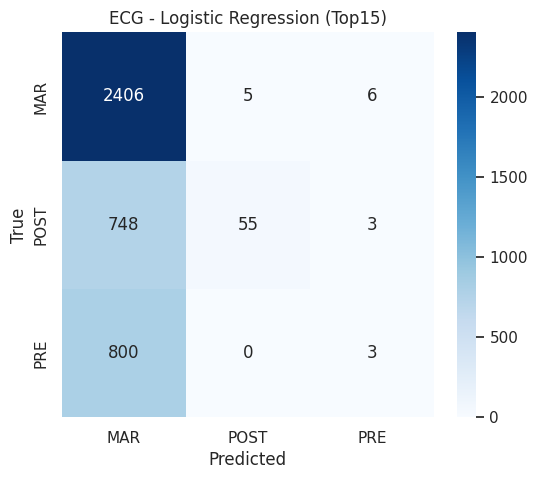


Running SVM


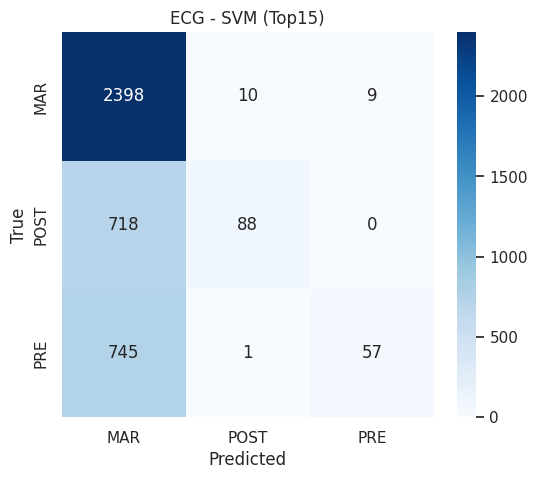


Running Random Forest


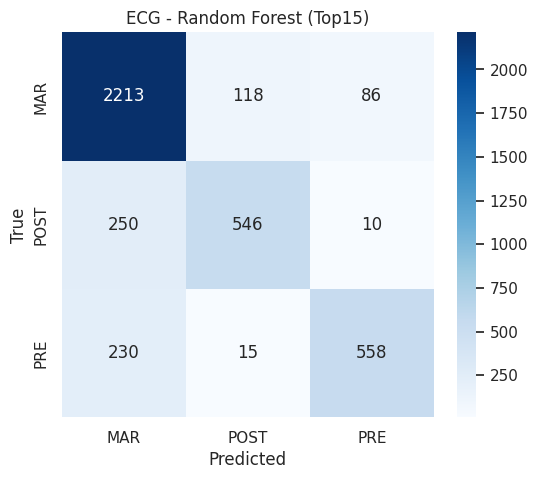


Running XGBoost


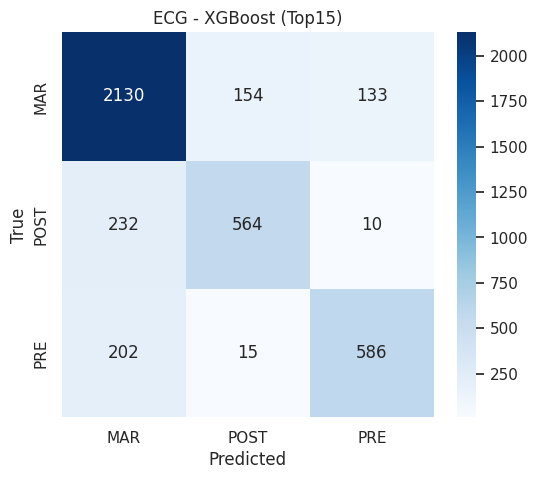


Running kNN


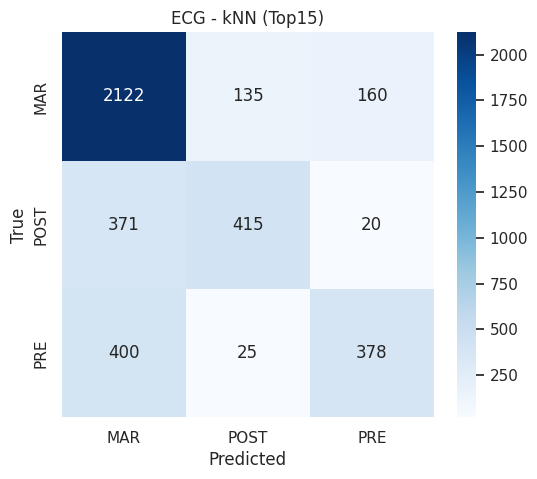


TOP 15 FEATURE CLASSIFICATION: EEG
Total Samples : 21470
Train Samples : 17176
Test Samples  : 4294
Using Features: 15

Running Logistic Regression


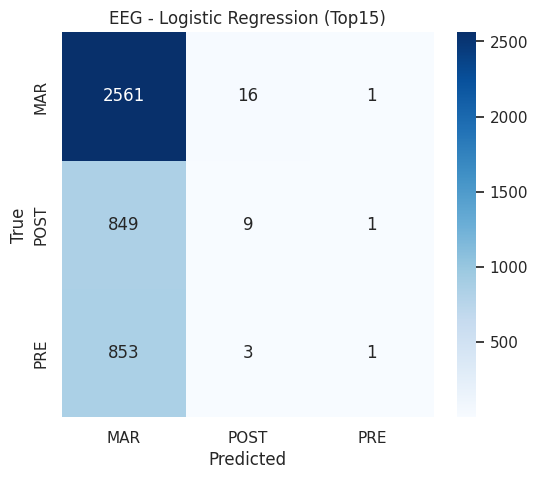


Running SVM


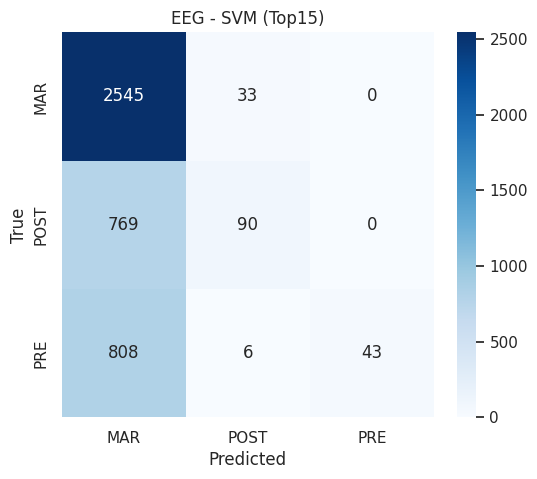


Running Random Forest


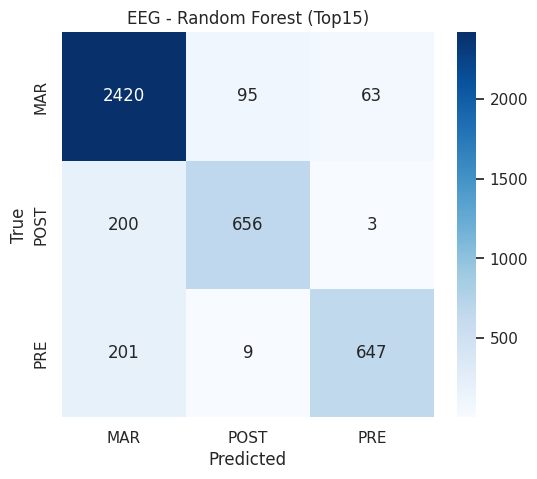


Running XGBoost


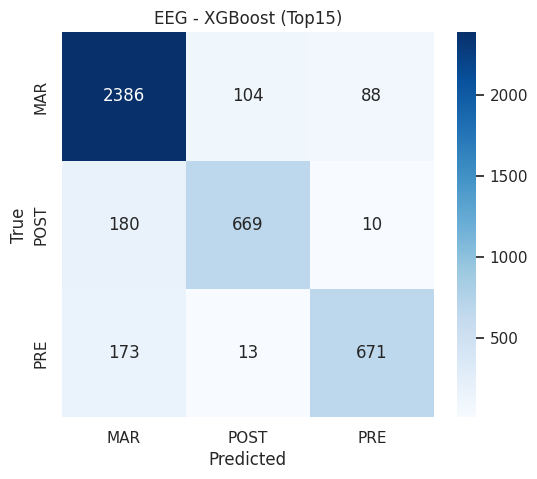


Running kNN


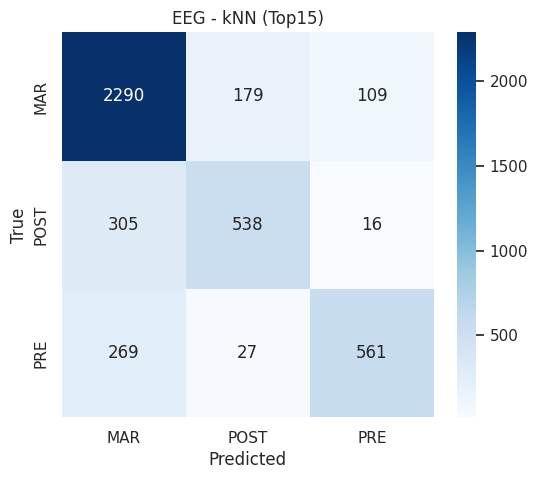


TOP 15 FEATURE CLASSIFICATION: EMG
Total Samples : 18681
Train Samples : 14944
Test Samples  : 3737
Using Features: 15

Running Logistic Regression


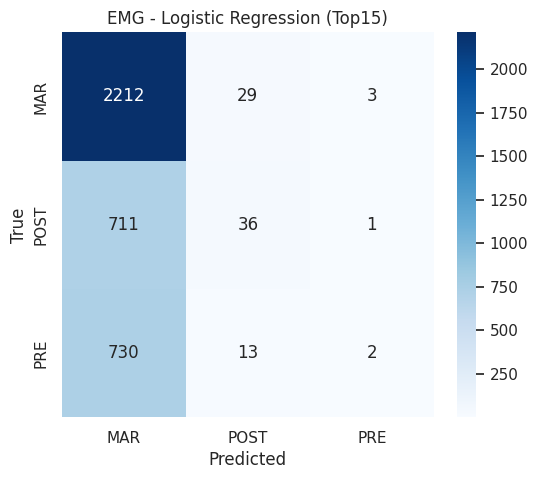


Running SVM


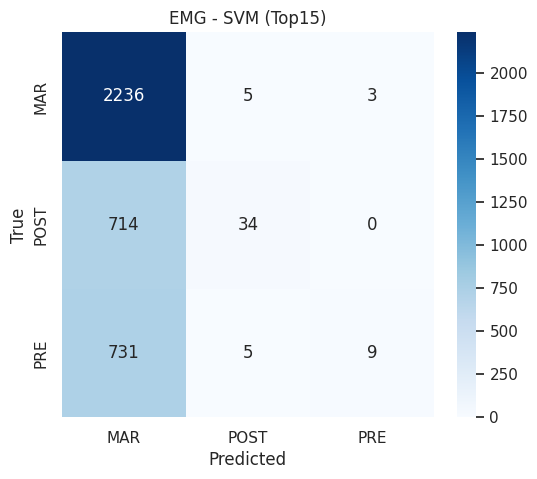


Running Random Forest


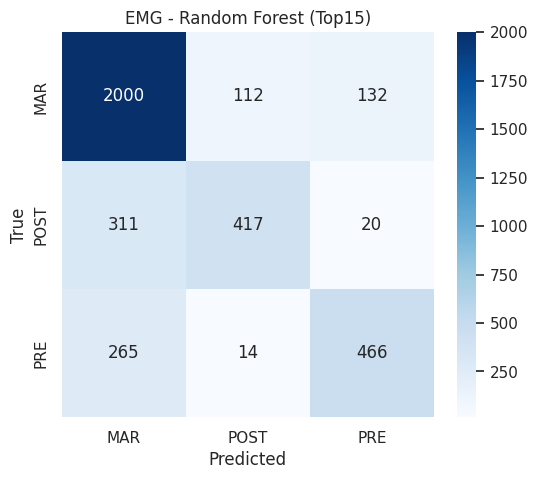


Running XGBoost


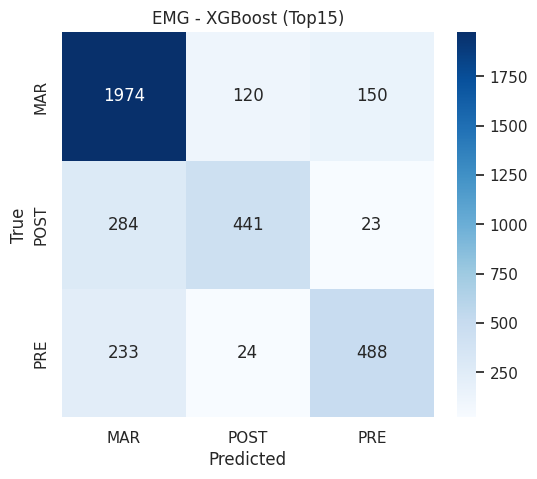


Running kNN


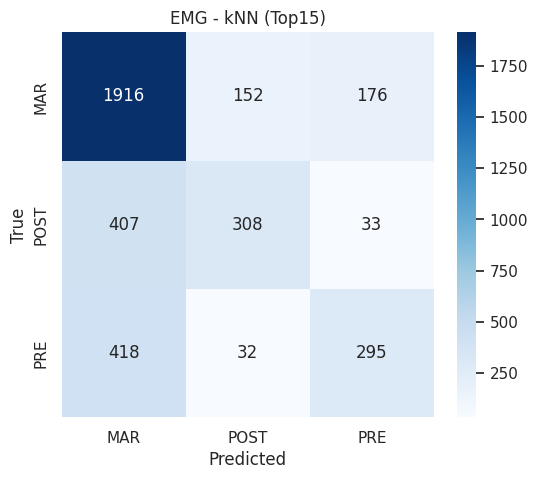


TOP 15 FEATURE CLASSIFICATION: Fusion
Total Samples : 18681
Train Samples : 14944
Test Samples  : 3737
Using Features: 15

Running Logistic Regression


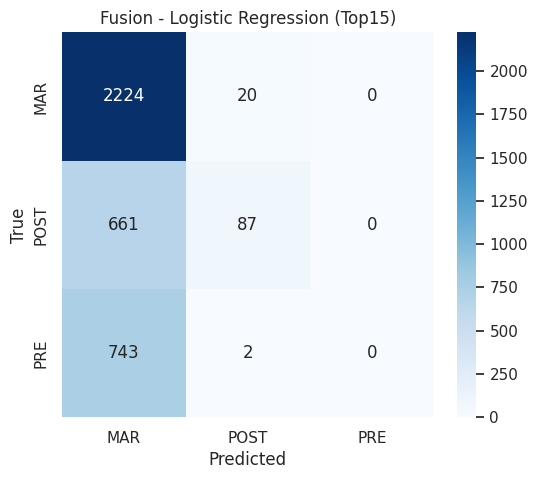


Running SVM


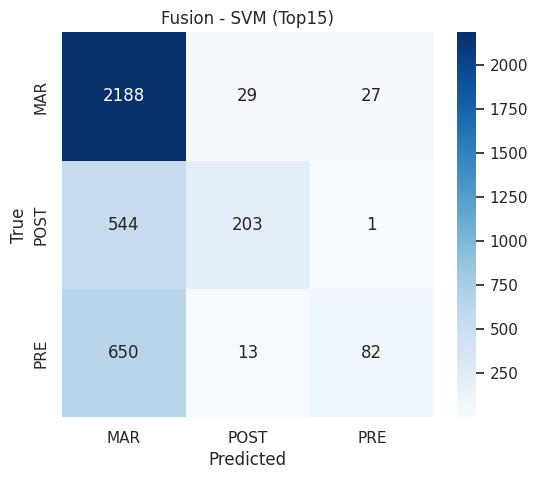


Running Random Forest


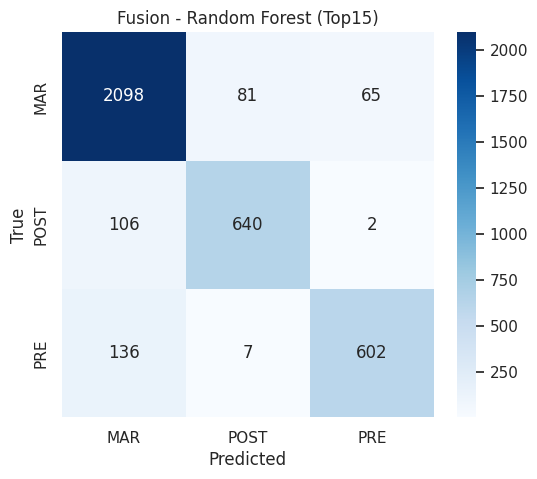


Running XGBoost


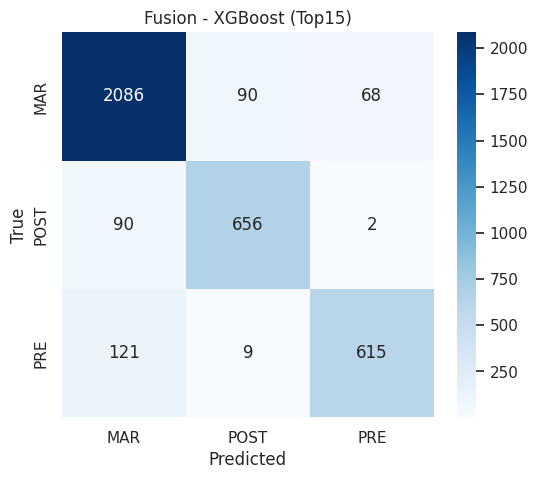


Running kNN


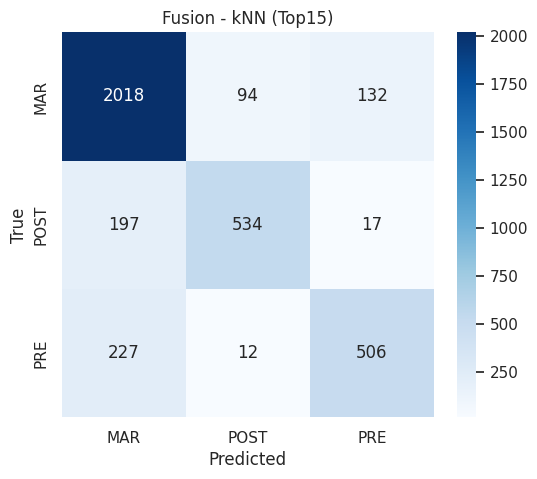

   Modality Feature_Set                Model  Accuracy  Precision    Recall  \
18   Fusion       Top15              XGBoost  0.898314   0.891608  0.877366   
17   Fusion       Top15        Random Forest  0.893765   0.891851  0.866202   
19   Fusion       Top15                  kNN  0.818303   0.811089  0.764128   
16   Fusion       Top15                  SVM  0.661761   0.740327  0.452167   
15   Fusion       Top15  Logistic Regression  0.618410   0.470392  0.369133   
13      EMG       Top15              XGBoost  0.776826   0.761525  0.708095   
12      EMG       Top15        Random Forest  0.771474   0.766133  0.691419   
14      EMG       Top15                  kNN  0.674070   0.636783  0.553857   
11      EMG       Top15                  SVM  0.609847   0.710057  0.351323   
10      EMG       Top15  Logistic Regression  0.602087   0.466800  0.345518   
8       EEG       Top15              XGBoost  0.867722   0.864943  0.829100   
7       EEG       Top15        Random Forest  0.8670

In [ ]:
#for top 15 features
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score, confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

import seaborn as sns
import matplotlib.pyplot as plt

#paths

files = {
    "ECG": "/content/drive/MyDrive/Sourcedata/extracted_data/ECG_features.csv",
    "EEG": "/content/drive/MyDrive/Sourcedata/extracted_data/EEG_features.csv",
    "EMG": "/content/drive/MyDrive/Sourcedata/extracted_data/EMG_features.csv",
    "Fusion": "/content/drive/MyDrive/Sourcedata/extracted_data/Fusion_features.csv"
}


top_features = {

"ECG": [
'ECG_var','ECG_std','ECG_rms','ECG_hjorth_complexity',
'ECG_hjorth_mobility','ECG_ptp','ECG_mid_power',
'ECG_spectral_entropy','ECG_low_power','ECG_kurtosis',
'ECG_skew','ECG_mid_rel_power','ECG_high_rel_power',
'ECG_high_power','ECG_mean'
],

"EEG": [
'T3_hjorth_complexity','T3_hjorth_mobility','T3_var',
'T4_hjorth_mobility','O2_hjorth_mobility','C3_var',
'C4_var','O1_rms','T4_std','O2_var',
'T3_std','T4_rms','O1_std','T4_hjorth_complexity',
'T3_rms'
],

"EMG": [
'EMG_waveform_length','EMG_mid_power','EMG_high_power',
'EMG_low_power','EMG_mid_rel_power','EMG_low_rel_power',
'EMG_ptp','EMG_high_rel_power','EMG_hjorth_mobility',
'EMG_std','EMG_var','EMG_rms',
'EMG_spectral_entropy','EMG_hjorth_complexity',
'EMG_mav'
],

"Fusion": [
'ECG_std','ECG_var','ECG_rms','EMG_waveform_length',
'EMG_mid_power','T3_hjorth_complexity','EMG_high_power',
'ECG_ptp','EMG_mid_rel_power','T3_std',
'ECG_hjorth_complexity','T3_rms','EMG_low_power',
'EMG_low_rel_power','T4_hjorth_mobility'
]

}


models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM": SVC(),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        eval_metric='mlogloss',
        use_label_encoder=False,
        random_state=42
    ),
    "kNN": KNeighborsClassifier()
}

#loop

results = []

for modality, path in files.items():

    print("\n" + "="*70)
    print("TOP 15 FEATURE CLASSIFICATION:", modality)
    print("="*70)

    df = pd.read_csv(path)

    y = df["phase"]

    feats = [f for f in top_features[modality] if f in df.columns]
    X = df[feats].copy()

    X = X.fillna(X.median())

    le = LabelEncoder()
    y_enc = le.fit_transform(y)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y_enc,
        test_size=0.20,
        stratify=y_enc,
        random_state=42
    )

    print("Total Samples :", len(df))
    print("Train Samples :", len(X_train))
    print("Test Samples  :", len(X_test))
    print("Using Features:", len(feats))

    for model_name, model in models.items():

        print(f"\nRunning {model_name}")

        if model_name in ["Logistic Regression", "SVM", "kNN"]:
            pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('model', model)
            ])
        else:
            pipe = Pipeline([
                ('model', model)
            ])

        pipe.fit(X_train, y_train)
        y_pred = pipe.predict(X_test)

        acc  = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, average='macro')
        rec  = recall_score(y_test, y_pred, average='macro')
        f1   = f1_score(y_test, y_pred, average='macro')
        bal  = balanced_accuracy_score(y_test, y_pred)

        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        cv_acc = cross_val_score(pipe, X, y_enc, cv=cv, scoring='accuracy').mean()

        results.append({
            "Modality": modality,
            "Feature_Set": "Top15",
            "Model": model_name,
            "Accuracy": acc,
            "Precision": prec,
            "Recall": rec,
            "F1": f1,
            "Balanced_Acc": bal,
            "CV_Accuracy": cv_acc
        })

        cm = confusion_matrix(y_test, y_pred)

        plt.figure(figsize=(6,5))

        cm_df = pd.DataFrame(
            cm,
            index=le.classes_,
            columns=le.classes_
        )

        cm_df.to_csv(
            os.path.join(
                analysis_dir,
                f"{modality}_{model_name}_Top15_CM_values.csv"
            )
        )
        sns.heatmap(
            cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_
        )
        plt.title(f"{modality} - {model_name} (Top15)")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.savefig(
            os.path.join(
                analysis_dir,
                f"{modality}_{model_name}_Top15_CM.png"
            ),
            dpi=600,
            bbox_inches="tight"
        )
        plt.show()

#table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(["Modality","Accuracy"], ascending=False)

print(results_df)

results_df.to_csv("top15_feature_classification_results.csv", index=False)


ECG


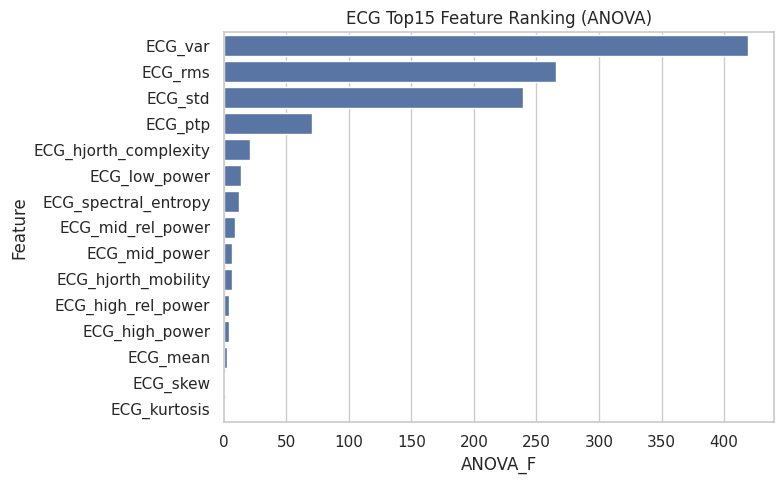

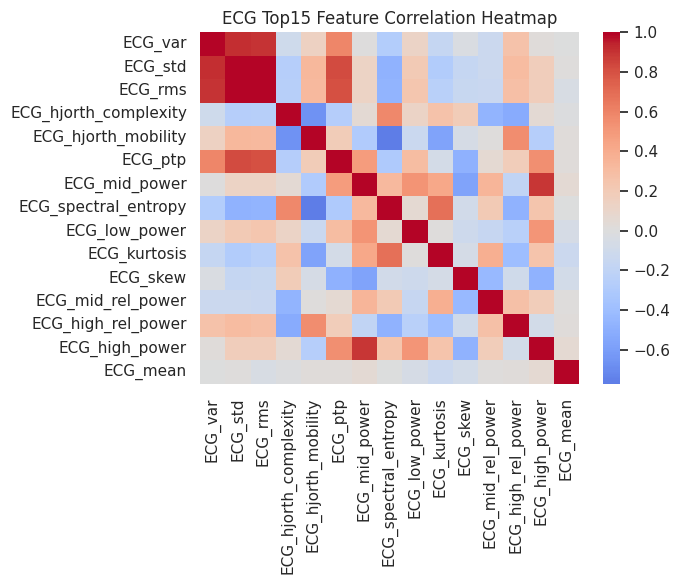


EEG


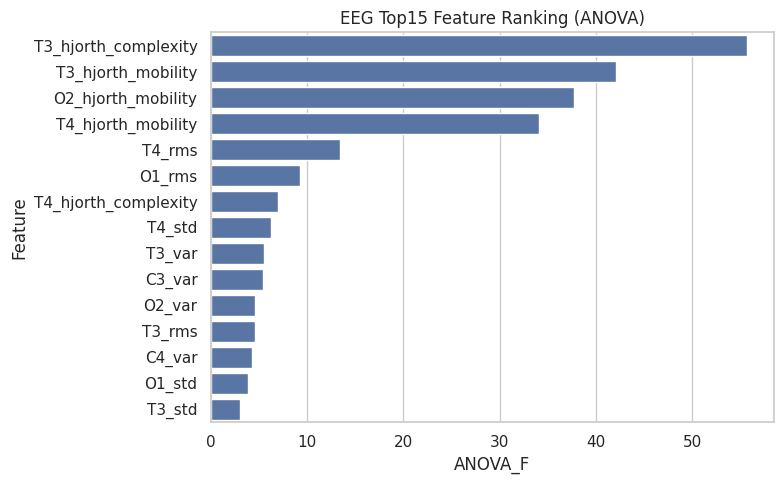

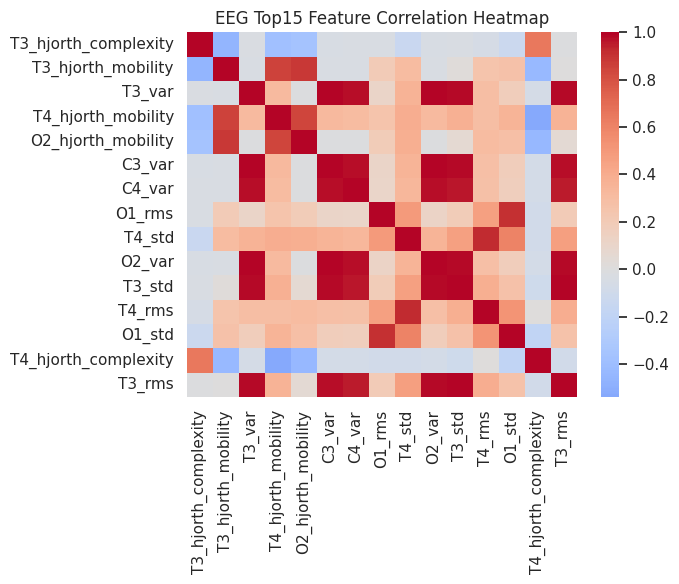


EMG


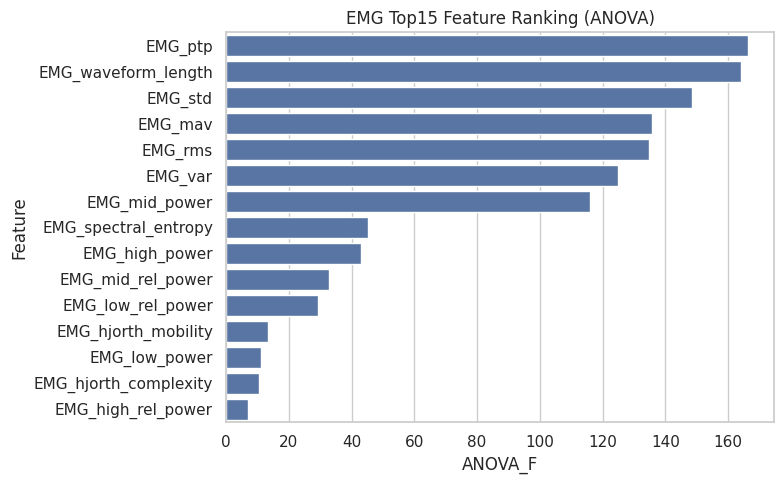

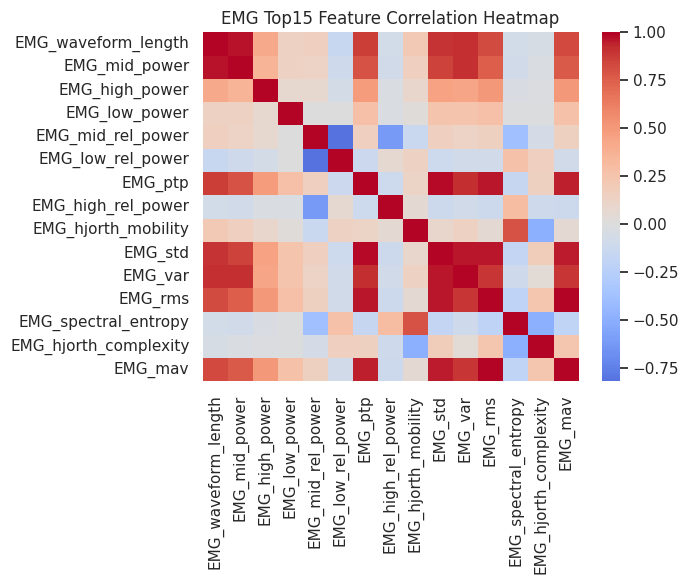


Fusion


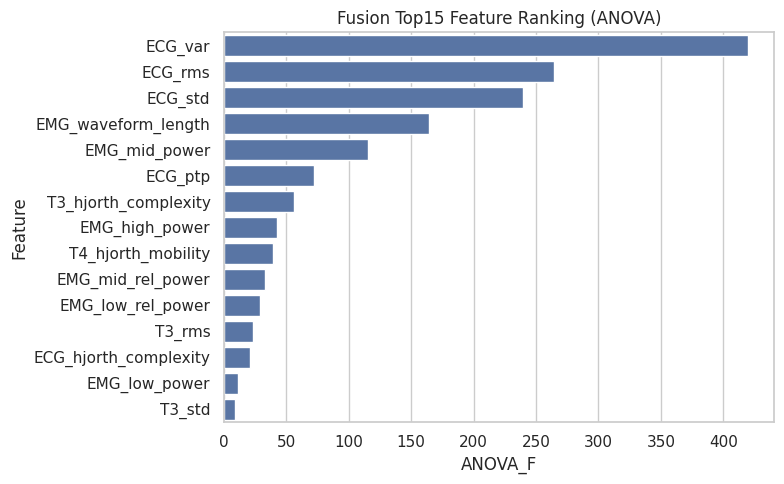

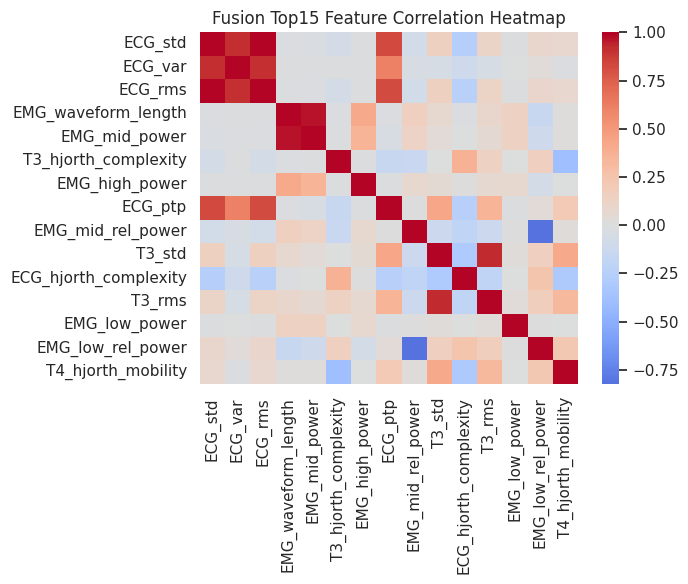

In [ ]:


files = {
    "ECG": "/content/drive/MyDrive/Sourcedata/extracted_data/ECG_features.csv",
    "EEG": "/content/drive/MyDrive/Sourcedata/extracted_data/EEG_features.csv",
    "EMG": "/content/drive/MyDrive/Sourcedata/extracted_data/EMG_features.csv",
    "Fusion": "/content/drive/MyDrive/Sourcedata/extracted_data/Fusion_features.csv"
}


anova_data = {

"ECG": {
'ECG_var':418.88,'ECG_std':239.18,'ECG_rms':265.58,
'ECG_hjorth_complexity':20.76,'ECG_hjorth_mobility':6.49,
'ECG_ptp':70.24,'ECG_mid_power':6.90,'ECG_spectral_entropy':12.25,
'ECG_low_power':13.72,'ECG_kurtosis':1.11,'ECG_skew':1.36,
'ECG_mid_rel_power':8.73,'ECG_high_rel_power':4.25,
'ECG_high_power':3.91,'ECG_mean':2.37
},

"EEG": {
'T3_hjorth_complexity':55.7,'T3_hjorth_mobility':42.1,'T3_var':5.49,
'T4_hjorth_mobility':34.12,'O2_hjorth_mobility':37.73,'C3_var':5.39,
'C4_var':4.31,'O1_rms':9.30,'T4_std':6.23,'O2_var':4.59,
'T3_std':3.00,'T4_rms':13.41,'O1_std':3.89,
'T4_hjorth_complexity':6.98,'T3_rms':4.57
},

"EMG": {
'EMG_waveform_length':164.28,'EMG_mid_power':115.88,
'EMG_high_power':42.99,'EMG_low_power':11.20,
'EMG_mid_rel_power':32.90,'EMG_low_rel_power':29.30,
'EMG_ptp':166.34,'EMG_high_rel_power':6.83,
'EMG_hjorth_mobility':13.32,'EMG_std':148.40,
'EMG_var':124.87,'EMG_rms':134.93,
'EMG_spectral_entropy':45.31,
'EMG_hjorth_complexity':10.56,'EMG_mav':135.91
},

"Fusion": {
'ECG_std':239.98,'ECG_var':419.54,'ECG_rms':264.71,
'EMG_waveform_length':164.28,'EMG_mid_power':115.88,
'T3_hjorth_complexity':56.55,'EMG_high_power':42.99,
'ECG_ptp':72.48,'EMG_mid_rel_power':32.90,
'T3_std':8.97,'ECG_hjorth_complexity':20.94,
'T3_rms':23.75,'EMG_low_power':11.20,
'EMG_low_rel_power':29.30,'T4_hjorth_mobility':39.67
}
}

#plots
for modality, path in files.items():

    print("\n" + "="*70)
    print(modality)
    print("="*70)

    df = pd.read_csv(path)

    top_feats = list(anova_data[modality].keys())

    # bar plot

    rank_df = pd.DataFrame({
        "Feature": top_feats,
        "ANOVA_F": list(anova_data[modality].values())
    }).sort_values("ANOVA_F", ascending=False)

    rank_df.to_csv(
    os.path.join(
        analysis_dir,
        f"{modality}_Top15_ANOVA_Ranking.csv"
    ),
    index=False
)


    plt.figure(figsize=(8,5))
    sns.barplot(data=rank_df, x="ANOVA_F", y="Feature")
    plt.title(f"{modality} Top15 Feature Ranking (ANOVA)")
    plt.tight_layout()
    plt.savefig(
        os.path.join(
            analysis_dir,
            f"{modality}_ANOVA_Barplot.png"
        ),
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

    #heatmap

    feats_present = [f for f in top_feats if f in df.columns]

    corr = df[feats_present].corr()

    corr.to_csv(
    os.path.join(
        analysis_dir,
        f"{modality}_Top15_Correlation_Matrix.csv"
    )
)


    plt.figure(figsize=(7,6))
    sns.heatmap(corr, cmap="coolwarm", center=0)
    plt.title(f"{modality} Top15 Feature Correlation Heatmap")
    plt.tight_layout()
    plt.savefig(
        os.path.join(
            analysis_dir,
            f"{modality}_Top15_Heatmap.png"
        ),
        dpi=600,
        bbox_inches="tight"
    )
    plt.show()

In [ ]:
import pandas as pd

data = [
["Fusion","Top15","XGBoost",0.898314,0.891608,0.877366,0.883934,0.877366,0.906054],
["Fusion","Top15","Random Forest",0.893765,0.891851,0.866202,0.878017,0.866202,0.899952],
["Fusion","Top15","kNN",0.818303,0.811089,0.764128,0.784533,0.764128,0.821423],
["Fusion","Top15","SVM",0.661761,0.740327,0.452167,0.459497,0.452167,0.665489],
["Fusion","Top15","Logistic Regression",0.618410,0.470392,0.369133,0.320176,0.369133,0.618757],

["EMG","Top15","XGBoost",0.776826,0.761525,0.708095,0.729875,0.708095,0.775976],
["EMG","Top15","Random Forest",0.771474,0.766133,0.691419,0.719891,0.691419,0.776083],
["EMG","Top15","kNN",0.674070,0.636783,0.553857,0.579286,0.553857,0.668272],
["EMG","Top15","SVM",0.609847,0.710057,0.351323,0.288135,0.351323,0.611263],
["EMG","Top15","Logistic Regression",0.602087,0.466800,0.345518,0.280902,0.345518,0.605589],

["EEG","Top15","XGBoost",0.867722,0.864943,0.829100,0.845404,0.829100,0.865114],
["EEG","Top15","Random Forest",0.867024,0.876148,0.819117,0.843681,0.819117,0.857848],
["EEG","Top15","kNN",0.789241,0.780161,0.723068,0.746666,0.723068,0.790126],
["EEG","Top15","SVM",0.623661,0.771698,0.380716,0.345814,0.380716,0.625384],
["EEG","Top15","Logistic Regression",0.598742,0.418504,0.335017,0.257113,0.335017,0.599860],

["ECG","Top15","Random Forest",0.823895,0.826365,0.762637,0.789152,0.762637,0.827247],
["ECG","Top15","XGBoost",0.814704,0.801338,0.770258,0.784402,0.770258,0.824017],
["ECG","Top15","kNN",0.724044,0.710884,0.621190,0.651911,0.621190,0.724350],
["ECG","Top15","SVM",0.631644,0.791203,0.390768,0.363199,0.390768,0.628658],
["ECG","Top15","Logistic Regression",0.612022,0.591721,0.355808,0.296560,0.355808,0.612063],
]

cols = ["Modality","Feature_Set","Model","Accuracy","Precision","Recall","F1","Balanced_Acc","CV_Accuracy"]

df = pd.DataFrame(data, columns=cols)
df.to_csv("Objective1_results.csv", index=False)
print(df)
print("Saved Objective1_results.csv")

   Modality Feature_Set                Model  Accuracy  Precision    Recall  \
0    Fusion       Top15              XGBoost  0.898314   0.891608  0.877366   
1    Fusion       Top15        Random Forest  0.893765   0.891851  0.866202   
2    Fusion       Top15                  kNN  0.818303   0.811089  0.764128   
3    Fusion       Top15                  SVM  0.661761   0.740327  0.452167   
4    Fusion       Top15  Logistic Regression  0.618410   0.470392  0.369133   
5       EMG       Top15              XGBoost  0.776826   0.761525  0.708095   
6       EMG       Top15        Random Forest  0.771474   0.766133  0.691419   
7       EMG       Top15                  kNN  0.674070   0.636783  0.553857   
8       EMG       Top15                  SVM  0.609847   0.710057  0.351323   
9       EMG       Top15  Logistic Regression  0.602087   0.466800  0.345518   
10      EEG       Top15              XGBoost  0.867722   0.864943  0.829100   
11      EEG       Top15        Random Forest  0.8670